# D56 GPTQ AWQ Code

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11

# GPTQ와 AWQ 구현 실습

## 오늘 확인할 문제

**GPTQ·AWQ로 만든 모델 파일을 다시 불러왔을 때, 답변 품질과 실행 상태를 어떻게 확인합니까?**

오늘은 7B 원본 모델을 GPTQ와 AWQ 방식으로 양자화해 파일로 저장합니다. 양자화에 사용할 한국어 보정 입력과 정답을 확인할 평가 질문을 분리하고, 저장한 모델을 다시 불러와 답변·메모리·속도를 측정합니다. 두 결과 중 다음 날 vLLM으로 실행할 모델을 고릅니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 보정 입력과 평가 질문을 분리해 7B를 GPTQ·AWQ 4비트 파일로 만들 수 있다.
- [목표 2] 파일을 다시 로드해 실행 구현을 확인하고 메모리·생성 시간·답변 변화를 비교할 수 있다.
- [목표 3] 서빙할 모델을 선택하고 파일·설정·평가 근거를 다음 실습으로 전달할 수 있다.

오늘은 팀 RunPod Pod에서 Qwen2.5-7B-Instruct를 직접 GPTQ와 AWQ로 양자화하고 Qwen 팀이 업로드한 32B AWQ 파일을 로드해 같은 하네스로 측정합니다. 마지막에는 프루닝·증류 노트의 결과와 함께 세 경량화 기법을 한 표에 놓습니다.

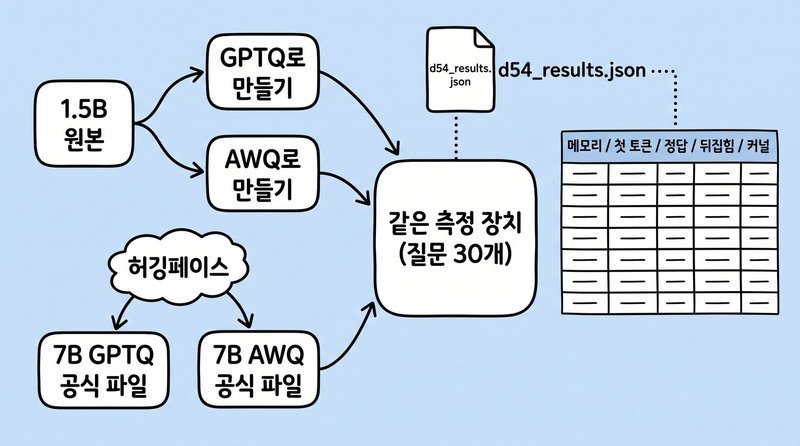

*직접 만든 파일과 받은 파일을 양자화 노트와 같은 하네스로 측정해 한 표에 놓습니다.*

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 파일 확인과 원본 7B 평가 | 75분 | 이론 1·4장, Step 0\~2 |
| 보정 입력 준비와 GPTQ 양자화 | 100분 | 이론 2장, Step 3\~4 |
| AWQ 양자화와 같은 질문 평가 | 100분 | 이론 3·5장, Step 5 |
| 32B 모델 평가와 D57 파일 준비 | 85분 | 이론 6장, Step 6\~7·9 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

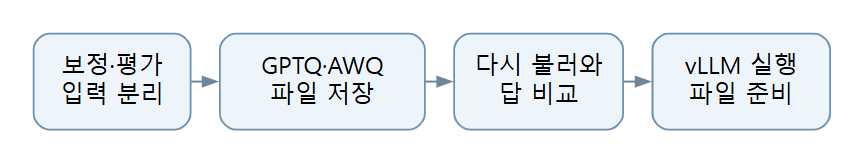

**실습 순서.** 보정·평가 입력 분리 → GPTQ·AWQ 파일 저장 → 다시 불러와 답 비교 → vLLM 실행 파일 준비 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| GPTQ |  가중치를 양자화할 때 생긴 오차를 다른 가중치에 보상하는 방법 |
| AWQ |  입력을 처리한 활성값을 보고 중요한 채널의 양자화 오차를 줄이는 방법 |
| 커널 |  GPU 등 특정 장치에서 연산을 실행하는 코드 |
| 체크포인트 |  모델을 다시 불러오는 데 필요한 가중치와 설정 파일 묶음 |

## 실행 환경

이 노트는 **팀 RunPod Pod**(48GB급 GPU 1장, 팀 네트워크 볼륨 `/workspace`)를 기준으로 씁니다. 프루닝·증류 노트의 마지막 Step에서 볼륨에 32B AWQ 파일과 7B 원본을 받아 두었습니다. 오늘 만든 파일과 결과는 모두 볼륨에 남겨 다음 날 vLLM 기초 노트에서 그대로 씁니다.

<div style="font-size: 18px; line-height: 1.6;">

| 항목 | 내용 |
|---|---|
| 런타임 | 팀 RunPod Pod, 48GB급 GPU 1장(A40 또는 RTX A6000, 재고가 없으면 L40S). 80GB A100이면 여유가 있음 |
| 볼륨 | 팀 네트워크 볼륨 100GB, `/workspace`에 마운트. 모델은 `HF_HOME=/workspace/hf` |
| 볼륨에 올려 둔 파일 | `Qwen/Qwen2.5-32B-Instruct-AWQ` 19.3GB, `Qwen/Qwen2.5-7B-Instruct` 15.2GB, `/workspace/bench_harness.py`, `/workspace/results/d55/d55_results.json` |
| 로드하는 모델 | 7B 16비트, 7B NF4, 7B GPTQ, 7B AWQ, 32B AWQ (차례로 하나씩) |
| 새로 만드는 파일 | 7B GPTQ 폴더, 7B AWQ 폴더, 결과 파일 `d56_results.json`. 모두 `/workspace/results/d56` 아래 |
| 필요한 키 | 없음. 별도 사용 승인 없이 파일을 내려받을 수 있는 공개 저장소만 씁니다 |
| 비용 | 금액은 RunPod 요금표에서 확인합니다. 하루가 끝나면 Pod를 종료하고 볼륨만 남깁니다(Step 9) |

</div>

<div style="font-size: 18px; line-height: 1.6;">

| 오래 걸리는 셀 | 하는 일 | 담당 | 걸린 시간 (측정해 적음) |
|---|---|---|---|
| Step 0 설치 | 패키지 설치 | A | |
| Step 0 볼륨 확인 | 빠진 저장소가 있으면 다운로드 | A | |
| Step 2 기준선 | 7B 16비트와 NF4 측정 | A | |
| Step 4 GPTQ 만들기 | 보정 데이터 128개로 7B 양자화 | B | |
| Step 4 첫 로드 | GPTQModel 커널 컴파일 | B | |
| Step 5 AWQ 만들기 | 보정 데이터 128개로 7B 양자화 | C | |
| Step 6 32B 측정 | 32B AWQ 로드와 측정 | D | |

</div>

코랩 T4에서 작은 모델로 하던 때의 시간은 이 Pod에 맞지 않으므로 **여러분 Pod에서 측정한 시간을 빈칸에 적습니다.** 만드는 시간과 메모리 최고점은 4비트 폴더의 `make_info.json`에 남습니다.

**로컬 작업** 표시가 붙은 곳은 사내 GPU 서버에서 달라지는 지점입니다. RunPod에서는 읽고 넘어가도 됩니다.

#### 팀 운영

4명이 한 팀이 되어 Pod 하나를 함께 씁니다. GPU가 한 장이라 **한 번에 모델 하나만** 올리고 맡은 Step의 셀은 담당자가 직접 실행합니다. 나머지 팀원은 출력을 함께 읽고 표에 옮겨 적습니다. 결과는 볼륨의 파일에 행마다 저장되므로 커널을 다시 시작해도 Step 1의 마지막 셀이 지금까지의 행을 다시 읽습니다.

<div style="font-size: 18px; line-height: 1.6;">

| 역할 | 맡은 Step | 하는 일 | 이름 |
|---|---|---|---|
| A | Step 0\~2 | Pod 기동, 볼륨 확인과 빠진 파일 다운로드, 하네스, 7B 기준선(16비트, NF4) 측정 | |
| B | Step 3, Step 4 | 보정 데이터 준비, 7B GPTQ 양자화와 측정 | |
| C | Step 5 | 7B AWQ 양자화와 측정 | |
| D | Step 6 | 32B 공식 AWQ 파일 로드와 측정 | |
| 모두 | Step 7\~9 | 세 기법 비교표, 선택 트랙, 공유와 Pod 종료 점검 | |

</div>

이름 칸을 채워 제출물에 넣습니다. 다음 날 vLLM 기초 노트에서는 같은 볼륨으로 역할을 바꿔 맡습니다. 두 팀은 같은 표 형식으로 결과를 남기고 Step 9에서 두 팀의 표를 나란히 놓습니다.

## Step 0. Pod 기동과 볼륨 확인

**담당 A.** 팀 Pod를 기동하고 볼륨에 받아 둔 모델을 확인합니다. 프루닝·증류 노트 끝의 RunPod 준비에서 볼륨에 두 모델을 받고 `bench_harness.py`와 그 노트의 결과 파일을 올려 두었습니다.

1. Pod를 만들 때 팀 네트워크 볼륨을 고릅니다. 네트워크 볼륨은 Pod를 만들 때만 붙일 수 있고 볼륨을 만든 데이터센터의 GPU만 고를 수 있습니다  
2. GPU는 48GB급 1장을 고릅니다  
3. Pod에 접속해 이 노트를 `/workspace` 아래에서 엽니다. 컨테이너 디스크는 Pod를 멈추면 지워지므로 노트와 결과는 볼륨에 둡니다

In [26]:
# 패키지 캐시를 볼륨에 두어 다음 날 다시 설치할 때 받는 시간을 줄입니다
!PIP_CACHE_DIR=/workspace/pip-cache pip install -q "transformers>=5.17,<6" "accelerate>=1.15,<2" "bitsandbytes>=0.50,<0.51" "datasets>=5.0,<6"
!PIP_CACHE_DIR=/workspace/pip-cache pip install -q "optimum>=2.3,<3" "gptqmodel==7.5.0" pandas matplotlib psutil

# 설치가 끝나면 커널을 한 번 다시 시작하고 이 셀 아래부터 실행하세요.
# gptqmodel 7.5.0은 numpy를 2.2.6으로, protobuf를 7 계열로 맞춥니다.
# 버전을 고정하는 까닭 : 7.6 이후는 torch 2.14.1 이상을 요구해 Pod 이미지의 torch를 통째로 바꿉니다.
# 다시 시작하지 않으면 옛 버전이 메모리에 남아 엉뚱한 곳에서 오류가 납니다

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting r

In [27]:
import torch, torch.nn.functional as F
from enum import Enum
if not hasattr(F, "ScalingType"):
    F.ScalingType = Enum("ScalingType", ["BlockWise1x128", "BlockWise128x128", "TensorWise", "RowWise"])

In [28]:
import os

# 모델 파일은 볼륨에 둡니다. 허깅페이스 라이브러리를 불러오기 전에 정해야 합니다
os.environ.setdefault("HF_HOME", "/workspace/hf")
# GPTQModel을 불러오기 전에 정합니다. CPU가 적은 환경에서 GPTQModel 7.5.0은 워커가 모자라
# "requests 2 workers but parent 'cpu' only has 1" 오류로 멈춥니다
os.environ.setdefault("GPTQMODEL_CPU_WORKERS", str(max(2, os.cpu_count() or 1)))

import gc, json, math, re, time, random, shutil, csv
from collections import Counter
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def pkgver(dist):
    """배포판 이름으로 설치된 버전을 읽습니다"""
    try:
        return version(dist)
    except PackageNotFoundError:
        return "미설치"


print("[설치된 버전]")
for d in ["torch", "transformers", "accelerate", "bitsandbytes", "datasets",
          "optimum", "gptqmodel", "numpy"]:
    print(f"  {d:<14} {pkgver(d)}")

[설치된 버전]
  torch          2.14.1+cu130
  transformers   5.22.1
  accelerate     1.15.0
  bitsandbytes   0.50.2
  datasets       5.2.0
  optimum        2.3.0
  gptqmodel      7.5.0
  numpy          2.2.6


In [29]:
import psutil

HAS_GPU = torch.cuda.is_available()
if HAS_GPU:
    prop = torch.cuda.get_device_properties(0)
    CAP = torch.cuda.get_device_capability(0)
    TOTAL_VRAM = prop.total_memory / 1e9
    NATIVE_BF16 = CAP[0] >= 8           # 양자화 노트 코드와 같은 규칙입니다
    print(f"GPU : {prop.name} / compute capability {CAP[0]}.{CAP[1]} / 메모리 {TOTAL_VRAM:.1f} GB")
else:
    CAP, TOTAL_VRAM, NATIVE_BF16 = None, None, False
    print("GPU가 보이지 않습니다. Pod에 GPU가 붙어 있는지 확인하고 다시 실행하세요.")
DTYPE16 = torch.float16  # AWQ와 같은 기준으로 비교합니다
print(f"16비트 기준 형식 : {DTYPE16} / CPU {os.cpu_count()}개 / 시스템 메모리 {psutil.virtual_memory().total / 1e9:.1f} GB")

# 모델 이름과 경로는 환경 변수에서 읽습니다. 모델을 바꿀 때는 이 상수만 바꿉니다
MODEL_ID = os.environ.get("MODEL_ID", "Qwen/Qwen2.5-7B-Instruct")                        # 직접 양자화할 원본
MODEL_ID_32B_AWQ = os.environ.get("MODEL_ID_32B_AWQ", "Qwen/Qwen2.5-32B-Instruct-AWQ")   # 공식 4비트 파일
WORK = Path(os.environ.get("D56_WORK", "/workspace/results/d56"))   # 결과 파일과 직접 만든 4비트 폴더
WORK.mkdir(parents=True, exist_ok=True)
N_CALIB = int(os.environ.get("D56_N_CALIB", "128"))            # 보정 데이터 개수 (이론 노트 2장 심화 ‘보정 데이터의 크기’)
CALIB_TOKENS = int(os.environ.get("D56_CALIB_TOKENS", "512"))  # 청크 하나의 목표 길이

for label, p in [("볼륨", WORK), ("컨테이너", Path.home())]:
    print(f"{label} {p} : 남은 디스크 {shutil.disk_usage(p).free / 1e9:.0f} GB")
if not str(WORK).startswith("/workspace"):
    print("  ! 결과 폴더가 볼륨 밖에 있습니다. Pod를 종료하면 지워집니다")

GPU : NVIDIA RTX PRO 6000 Blackwell Server Edition / compute capability 12.0 / 메모리 102.0 GB
16비트 기준 형식 : torch.float16 / CPU 48개 / 시스템 메모리 189.9 GB
볼륨 /workspace/results/d56 : 남은 디스크 218 GB
컨테이너 /root : 남은 디스크 218 GB


In [30]:
from huggingface_hub import snapshot_download

# 프루닝·증류 노트의 마지막 Step에서 볼륨에 받아 둔 두 저장소를 확인합니다.
# 없으면 FETCH_MISSING=1 일 때 여기서 받습니다(32B AWQ 19.3GB, 7B 원본 15.2GB)
FETCH_MISSING = os.environ.get("FETCH_MISSING", "1") == "1"


def on_volume_gb(repo):
    """볼륨의 허깅페이스 캐시에 받아 둔 가중치의 크기(GB). 없으면 None"""
    try:
        folder = Path(snapshot_download(repo, local_files_only=True))
    except Exception:
        return None
    return round(sum(f.stat().st_size for f in folder.rglob("*.safetensors")) / 1e9, 1)


print("HF_HOME :", os.environ["HF_HOME"])
for repo in [MODEL_ID, MODEL_ID_32B_AWQ]:
    size = on_volume_gb(repo)
    if size is None and FETCH_MISSING:
        print(f"{repo} : 볼륨에 없어 받습니다")
        snapshot_download(repo)
        size = on_volume_gb(repo)
    print(f"{repo} : {size} GB")

HF_HOME : /workspace/hf
Qwen/Qwen2.5-7B-Instruct : 15.2 GB
Qwen/Qwen2.5-32B-Instruct-AWQ : 19.3 GB


GPU의 **compute capability**를 먼저 출력했습니다. 8.0 이상이면 GPTQ와 AWQ 모두 Marlin이 후보이고 16비트 기준 형식도 bf16이 됩니다(이론 노트 4.2절). 볼륨의 두 저장소가 19.3GB와 15.2GB 안팎으로 출력되는지 봅니다. 크기가 모자라면 받다가 끊긴 것이니 다시 받습니다.

## 공통 준비 코드. 하네스 파일 다시 만들기

양자화 노트 코드가 만든 `bench_harness.py`가 작업 폴더에 없을 때 실행합니다. 양자화 노트의 `%%writefile` 셀 여섯 개와 같은 내용이고 빈칸은 정답으로 채워 두었습니다. 위에서부터 차례로 실행하면 `/workspace`에 파일이 생깁니다. 그다음 본 실습 Step 1부터 다시 실행합니다.

**첫 셀부터 차례로 실행합니다.** 두 번째 셀부터는 `-a`로 뒤에 덧붙이므로 중간 셀만 다시 실행하면 같은 내용이 두 번 들어갑니다.

In [31]:
%%writefile /workspace/bench_harness.py
"""54일차 벤치마크 하네스. 55~57일차가 import 해서 씁니다"""
import gc, json, math, os, re, time
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

HAS_GPU = torch.cuda.is_available()
# Step 0 과 같은 규칙 : bf16 은 compute capability 8 이상
DTYPE16 = torch.float16  # 같은 fp16 기준선으로 정밀도 효과를 비교합니다

# 모델 이름은 환경 변수가 있으면 거기서 읽습니다. 서빙 프로젝트에서 들인 습관입니다
MODEL_ID = os.environ.get("D54_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
# 측정할 때는 GPU 0번에 고정합니다. "auto" 로 두면 메모리가 모자랄 때 조용히 CPU 로 내려가
# 속도 측정값이 엉뚱해집니다(로컬 GPU 배포 노트 4.2절의 로드 방식)
DEVICE_MAP = {"": 0} if HAS_GPU else "cpu"

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

TEXT_KO = """한결물산 근무 규정 (실습용으로 지어낸 문서입니다)

제1조 (목적) 이 규정은 한결물산 임직원의 근무 시간, 재택근무, 휴가, 출장, 정보 보안에 관한 기준을 정한다.
제2조 (근무 시간) 기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다. 시차 출퇴근제를 신청한 직원은 오전 8시에서 10시 사이에 출근할 수 있다.
제3조 (재택근무) 재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.
제4조 (연차 휴가) 1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다.
제5조 (출장비) 국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.
제6조 (정보 보안) 회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
제7조 (경조 휴가) 본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다.
제8조 (교육 지원) 직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다.
제9조 (장비 대여) 업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 빌린 장비는 퇴사 전에 반납한다.
제10조 (법인카드) 법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다.
제11조 (회의) 정기 회의는 매주 월요일 오전 10시에 연다. 회의록은 회의가 끝난 날 안에 공유한다.
제12조 (개정) 이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."""

TEXT_EN = """Hangyeol Trading Work Rules (a document made up for this exercise)

Article 1 (Purpose) These rules set the standards for working hours, remote work, leave, business trips, and information security for employees of Hangyeol Trading.
Article 2 (Working hours) Regular working hours are from 9 a.m. to 6 p.m., and the lunch break is one hour from noon to 1 p.m. Employees who have applied for flexible hours may start work between 8 a.m. and 10 a.m.
Article 3 (Remote work) Employees may apply for remote work up to two days a week. Applications are made to the team leader by 3 p.m. on the day before. New employees may apply for remote work only after three months from joining.
Article 4 (Annual leave) Employees who have worked for one year or more receive 15 days of annual leave a year. Annual leave may be divided into half-day units. To take three or more consecutive days, apply at least two weeks in advance.
Article 5 (Travel expenses) For domestic business trips, accommodation is paid at actual cost up to 100,000 won per night. Meals are paid at a flat rate of 30,000 won per day. Settlement is requested with receipts within five days after the trip ends.
Article 6 (Information security) Company laptops must always be screen-locked when the employee leaves the desk. Files containing customer information are not sent by external email. An employee who learns of a security incident reports it to the security team within one hour.
Article 7 (Family event leave) Employees receive five days of leave for their own wedding and one day for a child's wedding. Five days are given when a parent dies.
Article 8 (Training support) External training related to the job is supported up to 1,000,000 won a year. Employees who complete training submit a report within two weeks.
Article 9 (Equipment rental) Work monitors and keyboards can be borrowed from the general affairs team. Borrowed equipment is returned before leaving the company.
Article 10 (Corporate card) The corporate card is used only for business purposes. Any single payment over 500,000 won requires prior approval from the finance team.
Article 11 (Meetings) The regular meeting is held every Monday at 10 a.m. Minutes are shared on the same day the meeting ends.
Article 12 (Amendment) When these rules change, all employees are notified at least two weeks before they take effect."""

TEXTS = {"ko": TEXT_KO, "en": TEXT_EN}

Overwriting /workspace/bench_harness.py


In [32]:
%%writefile -a /workspace/bench_harness.py


LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]

Appending to /workspace/bench_harness.py


In [33]:
%%writefile -a /workspace/bench_harness.py


def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.fullmatch(r"\s*(\{.*\})\s*", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False

Appending to /workspace/bench_harness.py


In [34]:
%%writefile -a /workspace/bench_harness.py


def make_bnb_config(precision):
    """정밀도 이름을 양자화 설정으로 바꿉니다. 인자는 기본값에 맡기지 않고 전부 적습니다"""
    if precision == "16bit":
        return None
    if precision == "int8":
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
    if precision == "int8_t0":                    # 부록 실습 D : 이상치 분리를 끈 8비트
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=0.0)
    if precision == "nf4":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_compute_dtype=DTYPE16, bnb_4bit_use_double_quant=True)
    if precision == "default4":                   # Step 6 : 한 줄짜리 설정
        return BitsAndBytesConfig(load_in_4bit=True)
    raise ValueError(f"모르는 정밀도 : {precision}")


def vram_gb(peak=False):
    """GPU 메모리(GB). GPU 가 없으면 None 을 반환합니다"""
    if not HAS_GPU:
        return None
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


def load_model(model_id, precision, pass_dtype=True):
    """모델을 로드해 딕셔너리 하나에 담아 반환합니다. 실패하면 예외 대신 error 를 담아 반환합니다"""
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    kwargs = {"device_map": DEVICE_MAP}
    if pass_dtype:
        kwargs["dtype"] = DTYPE16                 # torch_dtype= 은 폐기되었습니다
    qc = make_bnb_config(precision)
    if qc is not None:
        kwargs["quantization_config"] = qc
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return {"error": "GPU 메모리 부족", "precision": precision}
    except Exception as e:
        return {"error": f"{type(e).__name__}: {str(e)[:160]}", "precision": precision}
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return {"model_id": model_id, "precision": precision, "tok": tok, "model": model,
            "load_sec": time.time() - t0, "weights_gb": vram_gb(),
            "footprint_gb": model.get_memory_footprint() / 1e9}


def unload(h):
    """모델을 언로드하고 메모리가 실제로 줄었는지 수치로 보여 줍니다(모델 선택 실습의 방식)"""
    before = vram_gb()
    h["tok"] = h["model"] = None
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        after = vram_gb()
        print(f"  [언로드] GPU 메모리 {before:.2f} -> {after:.2f} GB")
        if before > 0.1 and after > before * 0.3:
            print("  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요")


def describe_layers(model):
    """층마다 어떤 형식으로 로드되었는지 셉니다. Qwen2 계열의 층 이름을 씁니다"""
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, nn.Linear) or "Linear" in type(m).__name__)
    q = model.model.layers[0].self_attn.q_proj
    info = {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}
    if hasattr(q, "compute_dtype"):
        info["4비트 계산 형식"] = str(q.compute_dtype)
        info["4비트 형식"] = getattr(q.weight, "quant_type", "-")
    return info

Appending to /workspace/bench_harness.py


In [35]:
%%writefile -a /workspace/bench_harness.py


@torch.no_grad()
def perplexity_top1(h, text, window=512, stride=256):
    """글 한 편의 퍼플렉서티와 위치마다의 1순위 예측을 측정합니다.

    윈도우를 stride 만큼 밀며 새로 들어온 토큰만 채점합니다(허깅페이스 문서의 방식).
    윈도우 크기와 stride 를 바꾸면 값이 바뀌므로 정밀도끼리 비교할 때는 고정합니다(이론 노트 6.2절).
    반환값 : (퍼플렉서티, 1순위 예측 텐서, 채점한 토큰 수)
    """
    tok, model = h["tok"], h["model"]
    ids = tok(text, return_tensors="pt")["input_ids"].to(model.device)
    n = ids.shape[1]
    nll_sum, count, preds, prev_end = 0.0, 0, [], 0
    for begin in range(0, n, stride):
        end = min(begin + window, n)
        x = ids[:, begin:end]
        logits = model(x).logits.float()          # 확률 계산은 32비트로 합니다
        k = min(end - prev_end, x.shape[1] - 1)    # 이번 윈도우에서 새로 채점할 토큰 수
        if k <= 0:                                # 토큰이 하나뿐인 윈도우는 채점할 것이 없습니다
            prev_end = end
            continue
        lg = logits[:, :-1][:, -k:]               # 위치 t 의 출력이 토큰 t+1 을 맞힙니다
        tgt = x[:, 1:][:, -k:]
        nll_sum += F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1),
                                   reduction="sum").item()
        count += tgt.numel()
        preds.append(lg.argmax(-1).flatten().cpu())
        prev_end = end
        if end == n:
            break
    return math.exp(nll_sum / count), torch.cat(preds), count


def chat_inputs(h, user_text):
    """시스템 프롬프트를 붙여 모델 입력을 만듭니다.

    transformers 5 의 apply_chat_template 은 return_tensors="pt" 일 때 텐서가 아니라
    input_ids 와 attention_mask 묶음을 반환합니다. 그래서 return_dict=True 를 적고 묶음으로 씁니다
    """
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
    enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt")
    return {k: v.to(h["model"].device) for k, v in enc.items()}


@torch.no_grad()
def ask(h, user_text, max_new_tokens=64):
    """샘플링 없이 답 하나를 만듭니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    enc = chat_inputs(h, user_text)
    try:
        out = h["model"].generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=h["tok"].pad_token_id)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return "[생성 실패] GPU 메모리 부족"
    return h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


SPEED_PROMPTS = ["재택근무 규정을 다섯 문장으로 설명해 주세요.",
                 "출장비를 정산하는 순서를 단계별로 적어 주세요.",
                 "정보 보안 수칙 다섯 가지를 설명해 주세요."]


@torch.no_grad()
def tokens_per_sec(h, new_tokens=128):
    """사용자 한 명이 답을 받는 속도. 첫 호출은 준비 시간이 섞여 버리고 측정합니다"""
    ask(h, SPEED_PROMPTS[0], max_new_tokens=8)
    total, t0 = 0, time.time()
    for p in SPEED_PROMPTS:
        enc = chat_inputs(h, p)
        out = h["model"].generate(**enc, max_new_tokens=new_tokens, min_new_tokens=new_tokens,
                                  do_sample=False, pad_token_id=h["tok"].pad_token_id)
        total += out.shape[1] - enc["input_ids"].shape[1]
    if HAS_GPU:
        torch.cuda.synchronize()
    return total / (time.time() - t0)


def measure_all(h, questions=None, texts=None):
    """한 정밀도의 모든 지표를 측정합니다. 기준선과 비교하는 일은 표를 만들 때 합니다"""
    questions = QUESTIONS if questions is None else questions
    texts = TEXTS if texts is None else texts
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    r = {"precision": h["precision"], "model_id": h["model_id"], "load_sec": h["load_sec"], "actual_dtype": str(h["model"].dtype),
         "weights_gb": h["weights_gb"], "footprint_gb": h["footprint_gb"],
         "layers": describe_layers(h["model"]), "ppl": {}, "preds": {}, "answers": {}, "correct": {}}
    for lang, text in texts.items():
        ppl, preds, n = perplexity_top1(h, text)
        r["ppl"][lang], r["preds"][lang] = ppl, preds
    for q in questions:
        ans = ask(h, q["q"], max_new_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    r["tps"] = tokens_per_sec(h)
    r["peak_gb"] = vram_gb(peak=True)
    return r

Appending to /workspace/bench_harness.py


In [36]:
%%writefile -a /workspace/bench_harness.py


# 실습 : 16비트에서 맞힌 것이 틀린 수(맞→틀)와 틀린 것이 맞은 수(틀→맞)를 세는 함수를 완성하세요
# 입력은 둘 다 {질문 id: True/False} dict입니다

def count_flips(base_correct, other_correct):
    ### START CODE HERE ### (맞→틀, 틀→맞 질문 수 세기 2줄)
    # 1) base 에서 True 인데 other 에서 False 인 질문 수. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    # 2) base 에서 False 인데 other 에서 True 인 질문 수
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    ### END CODE HERE ###
    if to_wrong is None or to_right is None:
        return None
    return {"맞→틀": to_wrong, "틀→맞": to_right}


def top1_agreement(base_preds, other_preds):
    """같은 글, 같은 윈도우에서 다음 토큰 1순위가 기준선과 같은 비율"""
    if base_preds is None or other_preds is None or len(base_preds) != len(other_preds):
        return None
    return float((base_preds == other_preds).float().mean())


def fmt(v, spec):
    """값이 없으면(GPU 가 없을 때의 메모리 등) 같은 너비로 '-' 를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

def measurement_conditions(model_id, dtype16, questions=None):
    """기준선을 재사용할 수 있는 조건. 실측 결과와 조건을 따로 저장합니다."""
    import hashlib
    from importlib.metadata import version, PackageNotFoundError
    from pathlib import Path
    from huggingface_hub import snapshot_download
    questions = QUESTIONS if questions is None else questions
    def digest(value):
        return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def installed(name):
        try: return version(name)
        except PackageNotFoundError: return None
    try:
        folder = Path(model_id) if Path(model_id).is_dir() else Path(snapshot_download(model_id, local_files_only=True))
        revision = folder.name if folder.parent.name == "snapshots" else digest(json.loads((folder / "config.json").read_text()))
    except (OSError, ValueError):
        revision = None
    return {"model": str(model_id), "revision": revision, "dtype16": str(dtype16),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "questions": len(questions), "questions_sha256": digest(questions),
            "generation_sha256": digest({"system": SYSTEM, "sample":False, "json_tokens":96, "other_tokens":48}),
            "harness_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
            "versions": {n:installed(n) for n in ["torch","transformers","accelerate","bitsandbytes"]}}


def matching_conditions(saved, current):
    return current.get("revision") is not None and all(saved.get(k) == v for k,v in current.items())

Appending to /workspace/bench_harness.py


In [37]:
import sys

In [38]:
sys.path.insert(0, "/workspace")
# 다시 만든 파일의 채점기를 검산합니다(양자화 노트와 같은 검산, 1초). 어긋남이 0건이어야 합니다
from bench_harness import check_answer

SELF_TEST = [("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("보안 또는 총무", "label", "보안", False),
             ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True)]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건", bad or "")

채점기 검산 4건 중 어긋남 0건 


## Step 1. 벤치마크 하네스 재사용

**담당 A.** 양자화 노트 코드가 저장한 벤치마크 하네스 파일 `bench_harness.py`를 **그대로 불러와 씁니다.** 질문 30개와 채점기, 측정 함수 `measure_all`, flip을 세는 `count_flips`입니다.

54일차가 만든 `bench_harness.py`는 프루닝·증류 노트 끝의 RunPod 준비에서 `/workspace`에 올려 두었습니다. 없으면 앞의 공통 준비 코드을 먼저 실행합니다. 모델 이름은 하네스의 기본값(1.5B)이 아니라 Step 0의 `MODEL_ID`(7B)를 씁니다.

In [39]:
from transformers import AutoTokenizer

HARNESS_DIR = os.environ.get("BENCH_HARNESS_DIR", "/workspace")
if not (Path(HARNESS_DIR) / "bench_harness.py").exists():
    print(f"{HARNESS_DIR}/bench_harness.py 가 없습니다. 앞의 공통 준비 코드을 먼저 실행하세요")
sys.path.insert(0, HARNESS_DIR)
# MODEL_ID는 하네스에서 가져오지 않습니다(Step 0의 7B를 씁니다)
from bench_harness import (TEXT_KO, TEXTS, QUESTIONS, vram_gb, load_model, unload, describe_layers,
                           chat_inputs, measure_all, count_flips, top1_agreement)

print(f"모델 : {MODEL_ID} / 질문 {len(QUESTIONS)}개 :", dict(Counter(q["type"] for q in QUESTIONS)))

모델 : Qwen/Qwen2.5-7B-Instruct / 질문 30개 : {'지문': 8, '계산': 8, '분류': 7, '형식': 7}


In [40]:
from bench_harness import measurement_conditions, matching_conditions

하네스의 채점기와 측정 함수는 양자화 노트에서 검산을 마쳤습니다. 공통 준비 코드로 파일을 다시 만들었다면 그 끝의 검산 셀로 확인합니다. 아래 셀은 하네스 바깥의 덧붙임입니다.

In [41]:
from transformers import GenerationConfig

results = {}                                   # 행 이름 -> measure_all 결과 + 덧붙인 필드
RESULT_FILE = WORK / "d56_results.json"
if RESULT_FILE.exists():                       # 커널을 다시 시작했거나 다른 팀원이 이어서 실행할 때
    previous = json.loads(RESULT_FILE.read_text(encoding="utf-8"))
    if matching_conditions(previous.get("_conditions", {}), measurement_conditions(MODEL_ID, DTYPE16)):
        results.update({k:v for k,v in previous.items() if not k.startswith("_")})
    else:
        print("기존 결과는 현재 조건과 달라 재사용하지 않습니다. 기존 파일은 별도로 백업합니다.")
        import shutil
        shutil.copy2(RESULT_FILE, RESULT_FILE.with_name("d56_results_previous_" + str(time.time_ns()) + ".json"))
    print("볼륨에서 다시 읽은 행 :", list(results))
LONG_PROMPT = TEXT_KO + "\n\n질문 : 이 규정에서 휴가와 관련된 조항을 모두 찾아 조항마다 한 문장으로 설명하십시오."


def first_line(e):
    text = str(e).strip()
    return f"{type(e).__name__}: {text.splitlines()[0][:200] if text else ''}"


def gb(v):
    return None if v is None else round(v, 2)


def weights_gb(path):
    '''가중치 파일의 크기. 저장소 이름이면 볼륨의 캐시에서 셉니다'''
    folder = Path(path)
    if not folder.exists():
        try:
            folder = Path(snapshot_download(str(path), local_files_only=True))
        except Exception:
            return None
    return round(sum(f.stat().st_size for f in folder.rglob("*.safetensors")) / 1e9, 2)


def align_generation(h, ref_repo):
    '''생성 설정을 ref_repo의 설정으로 통째로 바꾸고 바뀐 값을 반환합니다(이론 노트 5.1절)'''
    ref, own = GenerationConfig.from_pretrained(ref_repo), h["model"].generation_config
    keys = ("do_sample", "temperature", "top_p", "top_k", "repetition_penalty")
    diff = {k: [getattr(own, k, None), getattr(ref, k, None)] for k in keys
            if getattr(own, k, None) != getattr(ref, k, None)}
    h["model"].generation_config = ref
    return diff


def split_speed(h, prompt, n_new=64, repeat=3):
    """첫 토큰 시간과 디코드 속도를 나눠 측정합니다(이론 노트 5.2절)"""
    enc = chat_inputs(h, prompt)
    kw = {"do_sample": False, "pad_token_id": h["tok"].pad_token_id}
    ttfts, totals = [], []
    with torch.no_grad():
        h["model"].generate(**enc, max_new_tokens=8, **kw)        # 예열
        for _ in range(repeat):
            for n, bucket in ((1, ttfts), (n_new, totals)):
                if HAS_GPU:
                    torch.cuda.synchronize()
                t0 = time.perf_counter()
                h["model"].generate(**enc, max_new_tokens=n, min_new_tokens=n, **kw)
                if HAS_GPU:
                    torch.cuda.synchronize()
                bucket.append(time.perf_counter() - t0)
    ttft, total = sorted(ttfts)[repeat // 2], sorted(totals)[repeat // 2]
    return {"input_tokens": enc["input_ids"].shape[1], "ttft_s": round(ttft, 3),
            "decode_tps": round((n_new - 1) / max(total - ttft, 1e-6), 1)}


def save_results():
    saved = {k: {kk: vv for kk, vv in r.items() if kk != "preds"} for k, r in results.items()}
    saved["_conditions"] = measurement_conditions(MODEL_ID, DTYPE16)
    RESULT_FILE.write_text(json.dumps(saved, ensure_ascii=False, indent=1, default=str), encoding="utf-8")


def measure_file(name, path, precision, ref_repo):
    """하네스로 측정하고 필드를 덧붙입니다. precision은 원본·사전 양자화 파일이면 "16bit", 로드 시 4비트면 nf4"""
    h = load_model(str(path), precision)
    if "error" in h:
        results[name] = {"precision": name, "error": h["error"]}
        print(f"[{name}] 실패 : {h['error']}")
        save_results()
        return
    h["precision"] = name                     # 표의 레이블로 씁니다
    changed = align_generation(h, ref_repo)
    r = measure_all(h)
    r.update(split_speed(h, LONG_PROMPT))
    r.update({"disk_gb": weights_gb(path), "generation_changed": changed, "source": "D56"})
    unload(h)
    results[name] = r
    save_results()
    print(f"[{name}] 정답 {sum(r['correct'].values())}/{len(QUESTIONS)} | 첫 토큰 {r['ttft_s']} s "
          f"(입력 {r['input_tokens']} 토큰) | 초당 {r['tps']:.1f} 토큰 | 생성 설정 바뀐 값 {changed}")
    print(f"  선형 층 : {r['layers']['선형 층']}")

기존 결과는 현재 조건과 달라 재사용하지 않습니다. 기존 파일은 별도로 백업합니다.
볼륨에서 다시 읽은 행 : []


## Step 2. 7B 기준선 측정

**담당 A.** 7B 원본을 16비트와 NF4(로드할 때 4비트)로 측정합니다. 양자화 노트의 `d54_results.json`은 코랩에서 1.5B로 측정한 결과라 모델과 GPU가 달라 기준선으로 쓰지 않습니다. 오늘의 모든 행은 이 Pod에서 측정한 `16bit` 행과 비교합니다.

In [42]:
!pip uninstall -y torchao

Found existing installation: torchao 0.18.0
Uninstalling torchao-0.18.0:
  Successfully uninstalled torchao-0.18.0


In [43]:
# 이미 측정한 행은 건너뜁니다. 다시 측정하려면 D56_REMEASURE=1
REMEASURE = os.environ.get("D56_REMEASURE", "0") == "1"
for p in ["16bit", "nf4"]:
    if REMEASURE or "correct" not in results.get(p, {}):
        measure_file(p, MODEL_ID, p, ref_repo=MODEL_ID)
    else:
        print(f"[{p}] 볼륨에 저장된 결과를 씁니다")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

  [언로드] GPU 메모리 15.27 -> 0.03 GB
[16bit] 정답 23/30 | 첫 토큰 0.044 s (입력 803 토큰) | 초당 71.3 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'Linear': 197}
[nf4] 실패 : ImportError: Using `bitsandbytes` 4-bit quantization requires bitsandbytes: `pip install -U bitsandbytes>=0.46.1`


**눈여겨볼 곳**

- **선형 층** : 원본은 `Linear`, NF4는 `Linear4bit`가 출력됩니다  
- **올린 직후 GB** : 16비트 행은 원본 파일 15.2GB 안팎이고 NF4 행은 그 3분의 1 남짓이어야 합니다

## Step 3. 보정 데이터 준비

교재 : 4.4.8 8단계: 청킹하기

**담당 B, C 함께.** 이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’의 판단대로 **한국어 사내 문서로 보정합니다.** 같은 보정 청크로 Step 4의 GPTQ와 Step 5의 AWQ를 만듭니다.

 **로컬 작업** : 사내에서는 이 생성기 대신 실제 문서를 넣습니다.

In [44]:
tok_base = AutoTokenizer.from_pretrained(MODEL_ID)


def josa(word, pair):
    """받침이 있으면 pair의 앞 글자를, 없으면 뒤 글자를 붙입니다. pair는 "은는", "이가", "을를" 같은 짝입니다"""
    last = word[-1]
    final = "가" <= last <= "힣" and (ord(last) - 0xAC00) % 28 != 0
    return word + (pair[0] if final else pair[1])


DEPTS = ["인사팀", "재무팀", "총무팀", "보안팀", "영업1팀", "영업2팀", "개발팀", "품질팀", "고객지원팀", "구매팀"]
PEOPLE = ["정하윤", "강도현", "윤서아", "임태호", "한지민", "오세훈", "서민지", "백승우", "문가은", "장우진"]
THINGS = ["노트북", "모니터", "사무용 의자", "회의실 예약 시스템", "전자결재", "사내 메신저",
          "복합기", "출입 카드", "그룹웨어", "고객 관리 시스템"]
TOPICS = ["분기 실적", "신규 거래처 등록", "장비 교체", "교육 일정", "보안 점검",
          "고객 불만 처리", "예산 집행", "채용 진행", "사무실 이전", "시스템 점검"]
ARTICLES = [15, 16, 18, 24, 25, 27, 33, 35, 40, 41, 44, 52]    # 하네스의 규정 글이 쓰는 1\~12는 뺍니다
TITLES = ["자산 관리", "장비 신청", "교육 이수", "문서 보관", "외부 손님", "사무실 출입", "주차", "회의실 사용"]

HEADERS = {
    "규정": lambda r: f"[{r.choice(DEPTS)} 운영 규정]",
    "회의록": lambda r: f"[{r.choice(TOPICS)} 회의록]",
    "공지": lambda r: "[사내 공지]",
    "매뉴얼": lambda r: f"[{r.choice(THINGS)} 사용 설명서]",
    "보고서": lambda r: f"[{r.choice(DEPTS)} 월간 보고]",
    "메일": lambda r: "[업무 메일]",
}
SENTENCES = {
    "규정": [
        lambda r: (f"제{r.choice(ARTICLES)}조 ({r.choice(TITLES)}) {josa(r.choice(DEPTS), '은는')} {r.choice(THINGS)} "
                   f"사용 기준을 매년 {r.randint(1, 12)}월에 다시 정한다. 기준이 바뀌면 시행 {r.randint(3, 14)}일 "
                   "전에 부서 게시판에 공지한다."),
        lambda r: (f"제{r.choice(ARTICLES)}조 ({r.choice(TITLES)}) {josa(r.choice(THINGS), '을를')} 새로 신청하는 "
                   f"직원은 {r.choice(DEPTS)}에 신청서를 내고 {r.randint(2, 9)}일 안에 결과를 받는다. "
                   "급한 경우에는 팀장 확인을 받아 먼저 쓸 수 있다."),
        lambda r: (f"제{r.choice(ARTICLES)}조 ({r.choice(TITLES)}) 회사 비용으로 산 {josa(r.choice(THINGS), '은는')} "
                   f"회사 자산으로 등록한다. 퇴사하거나 부서를 옮길 때는 {r.choice(DEPTS)}에 반납한다."),
        lambda r: (f"제{r.choice(ARTICLES)}조 ({r.choice(TITLES)}) 외부 손님이 사무실에 들어올 때는 "
                   f"{r.choice(DEPTS)}에서 방문증을 받는다. 방문증은 당일 오후 {r.randint(4, 7)}시까지 돌려준다."),
        lambda r: (f"제{r.choice(ARTICLES)}조 ({r.choice(TITLES)}) 보존 기간이 {r.randint(1, 10)}년인 문서는 "
                   f"기간이 끝난 뒤 {r.choice(DEPTS)} 확인을 받아 폐기한다."),
    ],
    "회의록": [
        lambda r: (f"{r.randint(1, 12)}월 {r.randint(1, 28)}일 {r.choice(TOPICS)} 회의. "
                   f"참석 {', '.join(r.sample(PEOPLE, r.randint(3, 5)))}."),
        lambda r: (f"- {josa(r.choice(DEPTS), '은는')} {r.choice(THINGS)} 도입 일정을 {r.randint(1, 12)}월 "
                   f"{r.randint(1, 28)}일까지 확정하기로 했다."),
        lambda r: (f"- {r.choice(TOPICS)} 안건은 예산 {r.randint(3, 90) * 10}만 원 안에서 진행하기로 했다. "
                   f"담당은 {r.choice(PEOPLE)}이며 다음 회의에서 진행 상황을 보고한다."),
        lambda r: (f"- {r.choice(DEPTS)} 의견을 더 듣기로 하고 결론을 미뤘다. {josa(r.choice(PEOPLE), '이가')} "
                   f"{r.randint(1, 12)}월 {r.randint(1, 28)}일까지 의견을 모은다."),
        lambda r: f"- 다음 회의는 {r.randint(1, 12)}월 {r.randint(1, 28)}일 오전 {r.randint(9, 11)}시에 연다.",
    ],
    "공지": [
        lambda r: (f"{r.choice(TOPICS)} 안내입니다. {r.randint(1, 12)}월 {r.randint(1, 28)}일부터 "
                   f"{r.choice(THINGS)} 사용 방법이 바뀝니다. 자세한 내용은 {r.choice(DEPTS)} 게시판을 확인하십시오."),
        lambda r: (f"{r.randint(1, 12)}월 {r.randint(1, 28)}일 오전 {r.randint(6, 9)}시부터 두 시간 동안 "
                   f"{r.choice(THINGS)} 점검이 있습니다. 점검 중에는 접속이 되지 않으니 작업하던 자료를 미리 저장해 두십시오."),
        lambda r: f"문의는 {r.choice(DEPTS)} {r.choice(PEOPLE)} 담당자에게 사내 메신저로 보내 주십시오.",
        lambda r: (f"아직 신청하지 않은 직원은 {r.randint(1, 12)}월 {r.randint(1, 28)}일까지 사내 포털에서 "
                   "신청해 주십시오. 기한이 지나면 다음 분기로 넘어갑니다."),
    ],
    "매뉴얼": [
        lambda r: (f"{josa(r.choice(THINGS), '을를')} 처음 쓰는 직원은 사내 포털에서 계정을 신청합니다. "
                   f"승인이 나면 {r.randint(1, 7)}일 안에 첫 비밀번호를 새로 정합니다."),
        lambda r: (f"오류가 나면 화면을 캡처해 {r.choice(DEPTS)}에 보냅니다. 같은 오류가 {r.randint(2, 5)}번 넘게 "
                   "되풀이되면 장애로 등록합니다."),
        lambda r: "자료를 옮길 때는 공용 폴더를 쓰고 개인 메일로 보내지 않습니다.",
        lambda r: (f"{r.choice(THINGS)}에서 내려받은 파일은 {r.randint(7, 60)}일이 지나면 자동으로 지워집니다. "
                   "오래 둘 파일은 부서 폴더로 옮겨 두십시오."),
    ],
    "보고서": [
        lambda r: (f"{r.choice(TOPICS)} 보고입니다. {r.randint(1, 12)}월 기준 {r.choice(DEPTS)}의 처리 건수는 "
                   f"{r.randint(40, 900)}건으로 지난달보다 {r.randint(2, 40)}% 늘었습니다."),
        lambda r: (f"원인은 {r.choice(THINGS)} 교체 뒤에 신청이 몰린 데 있습니다. {r.randint(1, 12)}월부터는 "
                   f"담당자를 {r.randint(1, 4)}명 더 둡니다."),
        lambda r: f"남은 과제는 처리 기간을 {r.randint(2, 9)}일 안으로 줄이는 것입니다.",
        lambda r: f"{r.choice(DEPTS)}의 만족도 점수는 100점 만점에 {r.randint(60, 98)}점이었습니다.",
    ],
    "메일": [
        lambda r: (f"안녕하세요. {r.choice(DEPTS)} {r.choice(PEOPLE)}입니다. {r.choice(TOPICS)} 관련 자료를 "
                   f"{r.randint(1, 12)}월 {r.randint(1, 28)}일까지 보내 주시면 검토한 뒤 회신드리겠습니다."),
        lambda r: (f"첨부한 견적서의 금액은 부가세를 포함해 {r.randint(5, 900) * 10}만 원입니다. "
                   "고칠 곳이 있으면 회신 부탁드립니다."),
        lambda r: (f"{r.randint(1, 12)}월 {r.randint(1, 28)}일 회의는 {r.choice(DEPTS)} 사정으로 "
                   f"오후 {r.randint(1, 5)}시로 옮깁니다. 참석이 어려우면 미리 알려 주십시오."),
    ],
}
DOC_KINDS = list(SENTENCES)


def make_doc(seed, length):
    """seed로 문서 종류와 문장을 고르고 토큰 수가 length에 이를 때까지 문장을 잇습니다"""
    r = random.Random(seed)
    kind = DOC_KINDS[seed % len(DOC_KINDS)]          # 종류를 차례로 번갈아 골라 고르게 섞습니다
    parts = [HEADERS[kind](r)]
    while len(tok_base("\n".join(parts))["input_ids"]) < length:
        parts.append(r.choice(SENTENCES[kind])(r))
    return kind, "\n".join(parts)


made = [make_doc(1000 + i, CALIB_TOKENS) for i in range(N_CALIB)]
calib_ko = [text for _, text in made]
lens = [len(tok_base(t)["input_ids"]) for t in calib_ko]
print(f"보정 청크 {len(calib_ko)}개 / 평균 {sum(lens) / len(lens):.0f} 토큰 (최소 {min(lens)}, 최대 {max(lens)})")
print("종류별 개수 :", dict(Counter(kind for kind, _ in made)))
print("서로 다른 청크 :", len(set(calib_ko)))
print("\n[예시]\n" + calib_ko[1][:300])

보정 청크 128개 / 평균 532 토큰 (최소 512, 최대 565)
종류별 개수 : {'보고서': 22, '메일': 22, '규정': 21, '회의록': 21, '공지': 21, '매뉴얼': 21}
서로 다른 청크 : 128

[예시]
[업무 메일]
안녕하세요. 보안팀 강도현입니다. 사무실 이전 관련 자료를 7월 26일까지 보내 주시면 검토한 뒤 회신드리겠습니다.
안녕하세요. 개발팀 오세훈입니다. 시스템 점검 관련 자료를 11월 25일까지 보내 주시면 검토한 뒤 회신드리겠습니다.
첨부한 견적서의 금액은 부가세를 포함해 8040만 원입니다. 고칠 곳이 있으면 회신 부탁드립니다.
4월 20일 회의는 인사팀 사정으로 오후 1시로 옮깁니다. 참석이 어려우면 미리 알려 주십시오.
12월 24일 회의는 품질팀 사정으로 오후 5시로 옮깁니다. 참석이 어려우면 미리 알려 주십시


128개는 7B를 두 번 양자화하는 시간을 아끼려고 고른 출발점입니다. GPTQModel 7.5.0은 보정 데이터가 256개보다 적으면 Step 4에서 "Calibration dataset size should be more than 256" 경고를 출력합니다.

경고를 알고 고른 개수이니 그대로 진행합니다.

In [45]:
# 실습 : 보정 청크와 평가 질문이 겹치는지 세세요(이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’)


def grams(text, n=12):
    s = re.sub(r"\s+", "", text)
    return {s[i:i + n] for i in range(len(s) - n + 1)}


def leaked(calib):
    """보정 청크와 겹친 평가 질문의 id 목록을 반환합니다"""
    pool = set()
    for c in calib:
        pool |= grams(c)
    ### START CODE HERE ### (pool 과 겹치는 평가 질문의 id 목록 hits 만들기 1줄)
    # 1) 하네스의 질문마다 질문 글(["q"])로 grams 를 만들어 pool 과 하나라도 겹치면(&) 그 질문의 id 를 모읍니다
    hits = [x["id"] for x in QUESTIONS if grams(x["q"]) & pool]
    ### END CODE HERE ###
    return hits


hits = leaked(calib_ko)
if hits is None:
    print("hits가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    print(f"겹친 평가 질문 : {len(hits)}개 {hits}")
    pool = set().union(*(grams(c) for c in calib_ko))
    print("퍼플렉서티 글과 겹침 :", {lang: bool(grams(t) & pool) for lang, t in TEXTS.items()})
    # 검사 함수가 겹침을 실제로 잡는지 확인합니다. 규정 글을 일부러 섞으면 지문 질문 여덟 개(A1~A8)가 탐지되어야 합니다
    print("규정 글을 일부러 섞었을 때 :", leaked(calib_ko + [TEXT_KO]))

겹친 평가 질문 : 0개 []
퍼플렉서티 글과 겹침 : {'ko': False, 'en': False}
규정 글을 일부러 섞었을 때 : ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8']


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
hits = [x["id"] for x in QUESTIONS if grams(x["q"]) & pool]
```

**겹친 평가 질문은 0개여야 합니다.** 0이 아니면 양자화를 시작하기 전에 보정 데이터를 고칩니다. 겹친 채로 만든 파일은 겹친 질문에서 점수가 부풀려질 수 있습니다(이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’의 퀴즈).

</details>

In [46]:
# 보정 데이터 카드. 무엇으로 보정했는지 모델 옆에 남깁니다(이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’)
CALIB_CARD = {
    "source": "규칙으로 지어낸 한국어 사내 문서 (규정, 회의록, 공지, 매뉴얼, 보고서, 메일)",
    "language": "ko", "count": len(calib_ko), "avg_tokens": round(sum(lens) / len(lens)),
    "seed_start": 1000, "leak_hits": hits,
}
(WORK / "calib_ko.json").write_text(json.dumps({"card": CALIB_CARD, "texts": calib_ko}, ensure_ascii=False),
                                    encoding="utf-8")
print(json.dumps(CALIB_CARD, ensure_ascii=False))

{"source": "규칙으로 지어낸 한국어 사내 문서 (규정, 회의록, 공지, 매뉴얼, 보고서, 메일)", "language": "ko", "count": 128, "avg_tokens": 532, "seed_start": 1000, "leak_hits": []}


## Step 4. 7B GPTQ 양자화

**담당 B.** GPTQModel로 7B 원본을 GPTQ 4비트 파일로 만듭니다. 만든 폴더는 볼륨에 남아 vLLM 기초 노트에서 그대로 서빙합니다.

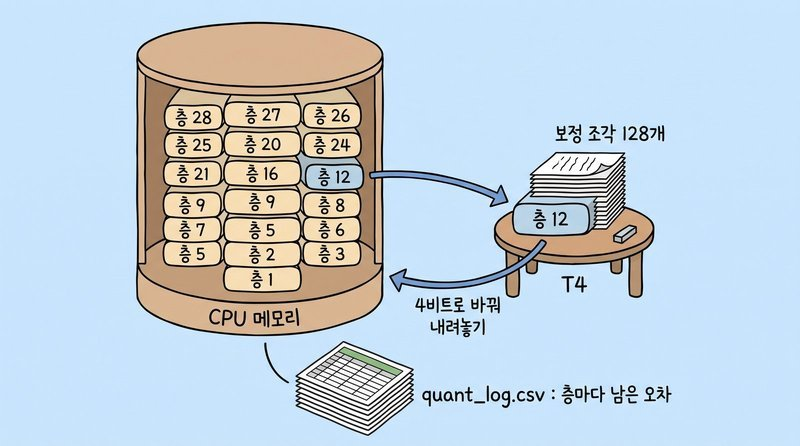

*GPTQModel은 층을 하나씩 GPU로 옮겨 보정하므로 GPU 메모리보다 원본을 저장할 공간과 시간이 먼저 제약이 됩니다.*

In [47]:
from gptqmodel import GPTQModel, GPTQConfig, AWQConfig

# 실습 : 이론 노트 2.4절의 기본값으로 GPTQ 설정을 만드세요
#        4비트, 그룹 128입니다. 대칭(sym=True)과 순서 변경 없음(desc_act=False)을 명시해 비교 조건을 고정합니다
### START CODE HERE ### (4비트, 그룹 128 GPTQ 설정 만들기 1줄)
# 1) GPTQConfig에 bits=4, group_size=128, sym=True, desc_act=False를 넘깁니다
qcfg_gptq = GPTQConfig(bits=4, group_size=128, sym=True, desc_act=False)
### END CODE HERE ###

if qcfg_gptq is None:
    print("qcfg_gptq가 비어 있습니다. 설정을 채우고 다시 실행하세요")
else:
    print({k: getattr(qcfg_gptq, k) for k in ("bits", "group_size", "sym", "desc_act")})


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.5.0
Transformers : 5.22.1
Torch        : 2.14.1+cu130
Triton       : 3.8.0
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_26_

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
qcfg_gptq = GPTQConfig(bits=4, group_size=128, sym=True, desc_act=False)
```

출력된 값에서 `sym`이 `True`, `desc_act`가 `False`인지 봅니다. Qwen 팀의 7B GPTQ 파일과 같은 설정이고 GPTQ Marlin이 받는 설정입니다(이론 노트 4.2절).

</details>

In [48]:
import resource


def make_quant(qcfg, calib, out_dir, src=None):
    """src(기본은 MODEL_ID)를 qcfg로 양자화해 out_dir에 저장합니다. 실패하면 이유를 담은 dict를 반환합니다.
    이미 만든 폴더가 있으면 다시 만들지 않습니다. 다른 조건이나 미완성 파일은 이전 이름으로 보관한 뒤 새로 만듭니다"""
    src, out_dir = src or MODEL_ID, Path(out_dir)
    if qcfg is None:
        return {"error": "설정이 비어 있습니다. 실습 셀을 먼저 채우세요"}
    import hashlib
    request={"src":str(src),"revision":measurement_conditions(str(src),DTYPE16).get("revision"),
        "dtype":str(DTYPE16),"method":type(qcfg).__name__,"gptqmodel":pkgver("gptqmodel"),
        "bits":qcfg.bits,"group_size":qcfg.group_size,"sym":qcfg.sym,
        "desc_act":getattr(qcfg,"desc_act",None),
        "calib_sha256":hashlib.sha256(json.dumps(calib,sort_keys=True,default=str).encode()).hexdigest()}
    def read_record(path):
        try:return json.loads(path.read_text(encoding="utf-8"))
        except (OSError,ValueError):return None
    def complete(folder):
        if not isinstance(read_record(folder/"config.json"),dict) or not list(folder.glob("*.safetensors")):return False
        if not any((folder/f).is_file() for f in ["tokenizer.json","tokenizer.model"]):return False
        index=folder/"model.safetensors.index.json"
        if not index.exists():return True
        info=read_record(index)
        return isinstance(info,dict) and isinstance(info.get("weight_map"),dict) and all((folder/f).is_file() for f in set(info["weight_map"].values()))
    marker=out_dir/"completed_request.json"
    info_file=out_dir/"make_info.json"
    if isinstance(read_record(info_file),dict) and complete(out_dir) and read_record(marker)==request:
        print(out_dir.name,"완료된 같은 요청을 재사용합니다.")
        return json.loads(info_file.read_text(encoding="utf-8"))
    if out_dir.exists() and any(out_dir.iterdir()):
        backup=out_dir.with_name(out_dir.name+"_previous_"+str(time.time_ns()))
        out_dir.rename(backup)
        print("미완성 또는 조건이 다른 파일을 보관했습니다:",backup)
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    model = None
    try:
        # 정밀도는 하네스와 같은 DTYPE16으로 적어 측정 조건을 맞춥니다
        model = GPTQModel.load(str(src), qcfg, dtype=DTYPE16)
        model.quantize(calib, batch_size=1)
        model.save(str(out_dir))
        from transformers import AutoTokenizer
        AutoTokenizer.from_pretrained(str(src)).save_pretrained(str(out_dir))
    except Exception as e:
        return {"error": first_line(e)}
    finally:
        model = None
        gc.collect()
        if HAS_GPU:
            torch.cuda.empty_cache()
    info = {"src": str(src), "method": type(qcfg).__name__, "bits": qcfg.bits,
            "group_size": qcfg.group_size, "sym": qcfg.sym, "calib_count": len(calib),
            "minutes": round((time.perf_counter() - t0) / 60, 1),
            "gpu_peak_gb": gb(vram_gb(peak=True)),
            # 이 프로세스가 지금까지 쓴 시스템 메모리의 최고점입니다(리눅스는 KB 단위로 알려 줍니다)
            "ram_peak_gb": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6, 1),
            "gptqmodel": pkgver("gptqmodel"), "gpu": torch.cuda.get_device_name(0) if HAS_GPU else "CPU",
            "date": time.strftime("%Y-%m-%d")}
    (out_dir / "make_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding="utf-8")
    if not complete(out_dir):return {"error":"파일 또는 샤드·토크나이저 저장이 완성되지 않았습니다."}
    tmp_marker=marker.with_name(marker.name+".tmp")
    tmp_marker.write_text(json.dumps(request,ensure_ascii=False,indent=2),encoding="utf-8")
    tmp_marker.replace(marker)
    return info

In [49]:
GPTQ_DIR = WORK / "7b-gptq-ko"
info_gptq = make_quant(qcfg_gptq, calib_ko, GPTQ_DIR)
print(info_gptq)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/workspace/hf/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.05,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  Packing Kernel: selected: `TorchLinear`                    

Writing model shards: 0it [00:00, ?it/s]

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "gptq",
  "quant_method": "gptq",
  "format": "gptq",
  "checkpoint_format": "gptq",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.5.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": 0.05,
    "damp_auto_increment": 0.01,
    "static_groups": false,
    "true_sequential": true,
    "mse": 0.0,
    "gptaq": null,
    "foem": null,
    "act_group_aware": true,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_26_l2dps",
    "pack_impl": "cpu",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_vr

`make_info.json`의 시간과 GPU 메모리 최고점, 시스템 메모리 최고점을 실행 환경 표의 빈칸에 옮겨 적습니다.

In [50]:
measure_file("gptq", GPTQ_DIR, "16bit", ref_repo=MODEL_ID)

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  Marlin fp16: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/marlin_fp16/a7eb7a24bb6a6065`.
INFO  Marlin fp16: torch.ops JIT extension ready in 66s (estimated ~117s, -51s).
INFO  gc.collect() reclaimed 8525 objects in 0.294s                             


AttributeError: 'MarlinLinear' object has no attribute 'weight'

In [ ]:
위 코드가 에러가 발생하였다면, 아래 코드를 이어서 진행합니다.

In [51]:
def _fix_describe(model):
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, torch.nn.Linear) or "Linear" in type(m).__name__)
    return {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}

measure_all.__globals__["describe_layers"] = _fix_describe
describe_layers = _fix_describe
gc.collect(); torch.cuda.empty_cache()

measure_file("gptq", GPTQ_DIR, "16bit", ref_repo=MODEL_ID)

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       


Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7933 objects in 0.299s                             
  [언로드] GPU 메모리 11.79 -> 6.24 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[gptq] 정답 24/30 | 첫 토큰 0.05 s (입력 803 토큰) | 초당 92.4 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'MarlinLinear': 196, 'Linear': 1}


**출력된 표의 `선형 층` 항목에서 GPU 계산에 실제로 사용된 구현 이름을 먼저 확인합니다.** compute capability 8.0 이상에서 4비트 대칭 GPTQ 파일이면 `MarlinLinear`가 후보입니다. 다른 이름이 보이면 이론 노트 4.2절의 조건과 맞춰 원인을 찾고 그 이름을 모델 카드에 그대로 적습니다. 층마다 남은 오차와 컴파일 캐시는 부록 실습 A에서 봅니다.

## Step 5. 7B AWQ 양자화

**담당 C.** 같은 원본과 같은 보정 청크로 AWQ 파일을 만듭니다.

In [52]:
# 실습 : AWQ 설정을 만드세요. 4비트, 그룹 128, 영점을 쓰는 비대칭입니다
#        Qwen 팀의 7B AWQ 파일과 같은 설정입니다(이론 노트 3.4절)
### START CODE HERE ### (4비트, 그룹 128, 비대칭 AWQ 설정 만들기 1줄)
# 1) AWQConfig 에 bits 와 group_size 를 넘기고 영점을 쓰는 비대칭이 되도록 sym 을 정합니다
qcfg_awq = AWQConfig(bits=4, group_size=128, sym=False)
### END CODE HERE ###

if qcfg_awq is None:
    print("qcfg_awq가 비어 있습니다. 설정을 채우고 다시 실행하세요")
else:
    print({k: getattr(qcfg_awq, k) for k in ("bits", "group_size", "sym")})

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_r2oqf047`
{'bits': 4, 'group_size': 128, 'sym': False}


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
qcfg_awq = AWQConfig(bits=4, group_size=128, sym=False)
```

옛 AutoAWQ 예제의 `zero_point=True`가 GPTQModel의 `sym=False`입니다. 이름의 뜻이 뒤집혀 있어서 옛 예제를 보고 `sym=True`를 적으면 반대 설정이 됩니다(이론 노트 3.4절).

</details>

In [53]:
AWQ_DIR = WORK / "7b-awq-ko"
info_awq = make_quant(qcfg_awq, calib_ko, AWQ_DIR)
print(info_awq)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/workspace/hf/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.05,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  AWQ: compiling torch.ops JIT extension in `/root/.cache/gpt

Writing model shards: 0it [00:00, ?it/s]

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "awq",
  "quant_method": "awq",
  "format": "gemm",
  "checkpoint_format": "gemm",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.5.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": null,
    "damp_auto_increment": null,
    "static_groups": null,
    "true_sequential": true,
    "mse": null,
    "gptaq": null,
    "foem": null,
    "act_group_aware": null,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_r2oqf047",
    "pack_impl": "cpu",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_vram

In [54]:
measure_file("awq", AWQ_DIR, "16bit", ref_repo=MODEL_ID)

INFO  Kernel: Auto-selection: adding candidate `AwqMarlinLinear`                
INFO  Kernel: selected -> `AwqMarlinLinear`.                                    


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 6108 objects in 0.293s                             
  [언로드] GPU 메모리 14.96 -> 9.35 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[awq] 정답 26/30 | 첫 토큰 0.047 s (입력 803 토큰) | 초당 88.3 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'AwqMarlinLinear': 196, 'Linear': 1}


### 다음 날 서빙할 파일 확인

GPTQ·AWQ는 양자화 방법이고 vLLM은 저장된 파일을 실행하는 엔진입니다. 파일을 만들었다는 사실만으로 호환성과 품질이 확인되지는 않습니다. 아래 기록에서 가중치·설정·토크나이저와 재로드 평가가 모두 확인된 후보를 다음 날 하나 골라 서빙합니다.

In [55]:
handoff={"day":56,"base_model":MODEL_ID,"candidates":{}}
for method,folder in [("gptq",GPTQ_DIR),("awq",AWQ_DIR)]:
    config=folder/"config.json"
    config_data=json.loads(config.read_text()) if config.exists() else {}
    weights=list(folder.glob("*.safetensors"))
    tokenizer_ok=any((folder/f).exists() for f in ["tokenizer.json","tokenizer.model"])
    evaluation=results.get(method,{})
    ok=bool(weights and config.exists() and tokenizer_ok and "correct" in evaluation and "error" not in evaluation)
    handoff["candidates"][method]={"path":str(folder),"ready":ok,
        "quantization_config":config_data.get("quantization_config"),
        "actual_dtype":evaluation.get("actual_dtype"),"weights_files":len(weights),
        "correct":evaluation.get("correct"),"make_info":str(folder/"make_info.json")}
path=WORK/"d56_serving_handoff.json"
path.write_text(json.dumps(handoff,ensure_ascii=False,indent=2),encoding="utf-8")
print(path)
for method,row in handoff["candidates"].items():print(method,"READY" if row["ready"] else "확인 필요",row["path"])

/workspace/results/d56/d56_serving_handoff.json
gptq READY /workspace/results/d56/7b-gptq-ko
awq READY /workspace/results/d56/7b-awq-ko


compute capability 8.0 이상이면 선형 층 열에 `AwqMarlinLinear`가 후보입니다(이론 노트 4.2절). GPTQ 행과 같은 GPU에서 측정했으므로 두 행의 첫 토큰 시간과 초당 토큰 차이는 커널과 형식의 차이입니다.

## Step 6. 32B 공식 4비트 파일 로드와 측정

**담당 D.** 32B는 Qwen 팀이 업로드한 AWQ 파일(19.3GB, 그룹 128, GEMM)을 씁니다(이론 노트 1.5절). 직접 만든 7B 파일과 같은 `measure_file`로 측정하고 생성 설정도 7B 원본의 설정으로 맞춥니다.

In [56]:
from transformers import AutoConfig


def fp16_weight_gb(repo):
    """설정 파일만 받아 16비트 가중치의 크기를 셉니다. 모델 선택 노트 코드의 파라미터 계산과 같습니다"""
    c = AutoConfig.from_pretrained(repo)
    h, inter = c.hidden_size, c.intermediate_size
    kv = c.num_key_value_heads * (h // c.num_attention_heads)
    per_layer = 2 * h * h + 2 * h * kv + 3 * h * inter        # q·o, k·v, gate·up·down
    embed = c.vocab_size * h * (1 if c.tie_word_embeddings else 2)
    return (c.num_hidden_layers * per_layer + embed) * 2 / 1e9


need_32b = fp16_weight_gb(MODEL_ID_32B_AWQ)          # 4비트 저장소의 설정도 원본과 같은 구조를 적습니다
gpu_txt = f"{TOTAL_VRAM:.1f} GB" if HAS_GPU else "없음"
print(f"32B를 16비트로 올리면 가중치만 {need_32b:.1f} GB / GPU 메모리 {gpu_txt}")
c32 = AutoConfig.from_pretrained(MODEL_ID_32B_AWQ)
print(f"층 {c32.num_hidden_layers}, hidden {c32.hidden_size}, KV 헤드 {c32.num_key_value_heads}, "
      f"config의 컨텍스트 {c32.max_position_embeddings:,}")

32B를 16비트로 올리면 가중치만 65.5 GB / GPU 메모리 102.0 GB
층 64, hidden 5120, KV 헤드 8, config의 컨텍스트 32,768


16비트 원본은 GPU 한 장에 올라가지 않으므로 4비트 파일만 로드합니다. 층 64, hidden 5120, KV 헤드 8, 컨텍스트 32,768이 출력되는지 봅니다. 이 수치는 vLLM 기초 노트 3.1절에서 KV 캐시를 계산할 때 다시 씁니다.

In [57]:
# 받기 전에 저장소의 설정부터 읽습니다. 설정 파일만 받으므로 몇 초면 끝납니다
for repo in [MODEL_ID, MODEL_ID_32B_AWQ]:
    try:
        g = GenerationConfig.from_pretrained(repo)
        print(f"{repo}\n  생성 설정 : do_sample={g.do_sample}, temperature={g.temperature}, top_p={g.top_p}, "
              f"top_k={g.top_k}, repetition_penalty={g.repetition_penalty}")
    except Exception as e:
        print(f"{repo}\n  생성 설정을 읽지 못함 : {first_line(e)}")
    qc = getattr(AutoConfig.from_pretrained(repo), "quantization_config", None)
    if qc:
        keys = ["quant_method", "bits", "group_size", "sym", "desc_act", "version", "zero_point"]
        print("  양자화 설정 :", {k: qc[k] for k in keys if k in qc})

Qwen/Qwen2.5-7B-Instruct
  생성 설정 : do_sample=True, temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.05
Qwen/Qwen2.5-32B-Instruct-AWQ
  생성 설정 : do_sample=True, temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.05
  양자화 설정 : {'quant_method': 'awq', 'bits': 4, 'group_size': 128, 'version': 'gemm', 'zero_point': True}


**생성 설정 줄** : 저장소마다 샘플링과 repetition penalty 값이 적혀 있습니다. `measure_file`이 모든 행을 7B 원본의 설정으로 맞추므로 32B 파일도 7B 행과 같은 조건에서 답합니다. **양자화 설정 줄**에서는 `quant_method`가 awq인지, `version`이 gemm인지, `zero_point`가 무엇인지 봅니다(이론 노트 3.4절).

In [58]:
measure_file("32B awq", MODEL_ID_32B_AWQ, "16bit", ref_repo=MODEL_ID)

INFO  Kernel: Auto-selection: adding candidate `AwqMarlinLinear`                
INFO  Kernel: selected -> `AwqMarlinLinear`.                                    


Loading weights:   0%|          | 0/1667 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 12 objects in 0.304s                               
  [언로드] GPU 메모리 28.69 -> 9.35 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[32B awq] 정답 26/30 | 첫 토큰 0.186 s (입력 803 토큰) | 초당 40.4 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'AwqMarlinLinear': 448, 'Linear': 1}


**메모리와 정답 열을 7B 행과 비교합니다.** 32B 4비트의 `올린 직후 GB`가 7B 16비트와 비교해 어디쯤인지, 정답과 정오답이 달라진 문항이 7B 16비트보다 나은지를 Step 7의 표에서 함께 읽습니다. 큰 모델의 4비트와 작은 모델의 16비트 가운데 무엇을 고를지가 이 두 행에서 갈립니다.

## Step 7. 양자화·프루닝·증류 결과 비교표

교재 : 3.4.3 애플리케이션에 가장 적합한 모델 선택하기, 5.7 자원 제약 장치용 모델 최적화

**팀 모두.** 측정한 행을 모두 한 표에 놓습니다. 퍼플렉서티 비율과 flip은 이 Pod에서 측정한 7B `16bit` 행을 기준선으로 계산합니다. 32B 행도 7B 16비트와 비교합니다.

In [59]:
import pandas as pd


def base_of(name):
    """기준선 행 이름. 모든 행을 이 Pod에서 측정한 7B 16bit 행과 비교합니다. 자기 자신이거나 없으면 None입니다"""
    b = "16bit"
    ok = b != name and "correct" in results.get(b, {}) and "correct" in results.get(name, {})
    return b if ok else None


def overview():
    rows = []
    for name, r in results.items():
        if "error" in r:
            rows.append({"이름": name, "선형 층": "실패 : " + r["error"][:60]})
            continue
        b = base_of(name)
        flips = count_flips(results[b]["correct"], r["correct"]) if b else None
        agree = top1_agreement(results[b].get("preds", {}).get("ko"), r.get("preds", {}).get("ko")) if b else None
        rows.append({
            "이름": name, "잰 곳": r.get("source", "-"), "디스크 GB": r.get("disk_gb"),
            "올린 직후 GB": gb(r.get("weights_gb")), "최고점 GB": gb(r.get("peak_gb")),
            "첫 토큰 s": r.get("ttft_s"), "초당 토큰": round(r["tps"], 1),
            "PPL비 한": round(r["ppl"]["ko"] / results[b]["ppl"]["ko"], 3) if b else None,
            "1순위 한": None if agree is None else f"{agree:.1%}",
            "정답": f"{sum(r['correct'].values())}/{len(QUESTIONS)}",
            "맞→틀": flips["맞→틀"] if flips else None, "틀→맞": flips["틀→맞"] if flips else None,
            "선형 층": ", ".join(f"{k} {v}" for k, v in r["layers"]["선형 층"].items()),
        })
    return pd.DataFrame(rows).set_index("이름").fillna("-")


def type_table(names=None):
    """질문 유형별 정답 수. 평균 하나에 묻힌 유형별 결과를 꺼냅니다(이론 노트 5장 심화 ‘평균이 가리는 유형별 차이’)"""
    names = [n for n in (names or results) if "correct" in results.get(n, {})]
    types = sorted({q["type"] for q in QUESTIONS})
    data = {n: {t: f"{sum(results[n]['correct'][q['id']] for q in QUESTIONS if q['type'] == t)}/"
                   f"{sum(q['type'] == t for q in QUESTIONS)}" for t in types} for n in names}
    return pd.DataFrame(data).T


display(overview())
display(type_table())
overview().to_csv(WORK / "d56_results.csv", encoding="utf-8-sig")

,잰 곳,디스크 GB,올린 직후 GB,최고점 GB,첫 토큰 s,초당 토큰,PPL비 한,1순위 한,정답,맞→틀,틀→맞,선형 층
이름,,,,,,,,,,,,
16bit,D56,15.23,15.27,16.01,0.044,71.3,-,-,23/30,-,-,Linear 197
nf4,-,-,-,-,-,-,-,-,-,-,-,실패 : ImportError: Using `bitsandbytes` 4-bit q...
gptq,D56,5.58,11.79,12.53,0.05,92.4,1.033,92.6%,24/30,0.0,1.0,"MarlinLinear 196, Linear 1"
awq,D56,5.57,14.96,15.7,0.047,88.3,1.011,92.8%,26/30,0.0,3.0,"AwqMarlinLinear 196, Linear 1"
32B awq,D56,19.33,28.69,29.44,0.186,40.4,0.765,80.0%,26/30,1.0,4.0,"AwqMarlinLinear 448, Linear 1"


,계산,분류,지문,형식
16bit,4/8,5/7,7/8,7/7
gptq,5/8,5/7,7/8,7/7
awq,6/8,5/7,8/8,7/7
32B awq,5/8,6/7,8/8,7/7


**읽는 순서**

1. **실패한 행** : 메모리가 모자랐는지, 패키지가 빠졌는지 오류 문장을 먼저 봅니다  
2. **선형 층** : 행마다 기대한 커널이 선택되었는지 봅니다  
3. **메모리와 디스크** : 4비트 행의 `올린 직후 GB`가 16비트 행보다 얼마나 줄었는지 봅니다  
4. **첫 토큰과 초당 토큰** : 4비트 파일이 16비트와 NF4 사이 어디에 놓였는지 봅니다  
5. **정답과 flip** : 정답 수가 같아도 flip이 있으면 정오답이 달라진 문항을 직접 읽습니다(이론 노트 5장 심화 ‘평균이 가리는 유형별 차이’)  
6. **32B 행** : 메모리를 더 쓰는 대신 정답과 flip에서 7B 16비트보다 얻은 것이 있는지 봅니다

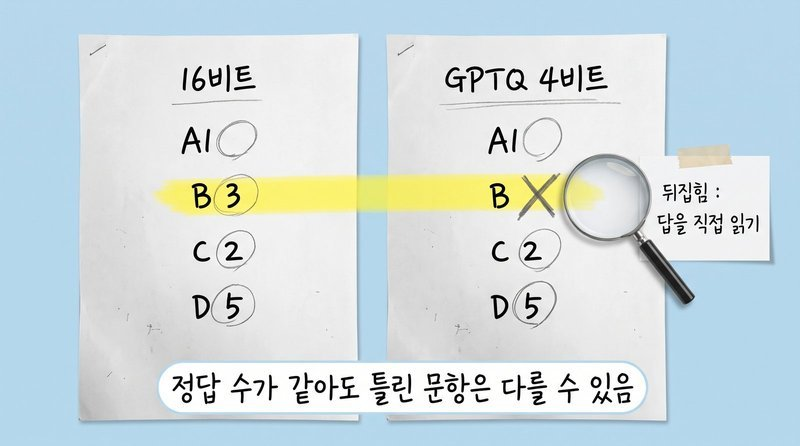

*무엇이 망가졌는지는 정답 수 셀 하나보다 정오답이 달라진 문항의 목록을 읽어야 보입니다.*

In [60]:
# 실습 : 기준선이 맞히고 이 행이 틀린 질문(맞→틀)을 질문 유형(지문, 계산, 분류, 형식)별로 세세요
def flip_types(name):
    b = base_of(name)
    if b is None:
        return {}
    base, other = results[b]["correct"], results[name]["correct"]
    ### START CODE HERE ### (맞→틀 질문을 유형별로 세어 {유형: 개수} 만들기 1줄)
    # 1) 기준선(base)은 맞히고 이 행(other)은 틀린 질문의 "type" 을 Counter 로 세어 dict 로 바꿉니다
    by_type = dict(Counter(q["type"] for q in QUESTIONS if base[q["id"]] and not other[q["id"]]))
    ### END CODE HERE ###
    return by_type


for name in results:
    if base_of(name) is None:
        continue
    by_type = flip_types(name)
    if by_type is None:
        print("by_type이 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
        break
    b = results[base_of(name)]
    print(f"\n[{name}] 맞→틀 유형 {by_type}")
    for q in QUESTIONS:
        if b["correct"][q["id"]] and not results[name]["correct"][q["id"]]:
            print(f"  {q['id']} ({q['type']}) 정답 {q['answer']}")
            print(f"     16bit : {b['answers'][q['id']][:60]!r}")
            print(f"     {name:<5} : {results[name]['answers'][q['id']][:60]!r}")


[gptq] 맞→틀 유형 {}

[awq] 맞→틀 유형 {}

[32B awq] 맞→틀 유형 {'분류': 1}
  C7 (분류) 정답 인사
     16bit : '인사'
     32B awq : '총무'


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
by_type = dict(Counter(q["type"] for q in QUESTIONS if base[q["id"]] and not other[q["id"]]))
```

**정오답이 달라진 문항을 유형으로 묶어 읽습니다.** 형식 질문이 뒤집혔다면 JSON의 괄호나 따옴표가 깨졌는지 보고 계산 질문이 뒤집혔다면 풀이 단계를 건너뛰었는지 봅니다.

</details>

**세 기법을 한 표에 놓습니다.** 프루닝·증류 노트 코드가 남긴 결과 파일(`d55_results.json`)을 읽어 오늘의 행 옆에 둡니다. 그 노트는 코랩에서 1.5B로 측정했으므로 메모리·속도의 원래 수치를 그대로 비교하지 않고 **각 노트의 16비트 기준 모델 값에 대한 비율과 정답 수의 차이**로 표시합니다(이론 노트 6.1절).

결과 파일은 볼륨의 `/workspace/results/d55/`에 올려 둡니다. 다른 곳에 있으면 `D56_PRUNE_FILE`에 경로를 적습니다.

In [61]:
# 프루닝·증류 노트 코드의 결과 파일. 파일 이름과 키는 그 노트가 정한 그대로 읽습니다
PRUNE_CANDIDATES = [Path(os.environ.get("D56_PRUNE_FILE", "/workspace/results/d55/d55_results.json")),
                    Path("/workspace/d55_results.json")]
PRUNE_FILE = next((p for p in PRUNE_CANDIDATES if p.exists()), None)
OUR_BRANCH = {"nf4": "양자화(로드 시)", "gptq": "양자화(GPTQ)", "awq": "양자화(AWQ)", "32B awq": "큰 모델 4비트"}


def ratio(a, b):
    return round(a / b, 2) if a is not None and b else None


def relative_rows(rows, source, gpu, branch_of):
    """rows의 16bit 행을 기준선으로 비율과 차이를 셉니다. branch_of가 None을 반환하는 행은 뺍니다"""
    base = rows.get("16bit", {})
    if "correct" not in base:
        return []
    out = []
    for name, r in rows.items():
        branch = branch_of(name, r)
        if branch is None or "correct" not in r:
            continue
        f = count_flips(base["correct"], r["correct"])
        out.append({"이름": name, "기법": branch, "잰 곳": source, "GPU": gpu,
                    "메모리 비": ratio(r.get("weights_gb"), base.get("weights_gb")),
                    "초당 토큰 비": ratio(r.get("tps"), base.get("tps")),
                    "정답 차": sum(r["correct"].values()) - sum(base["correct"].values()),
                    "맞→틀": f["맞→틀"]})
    return out


def ours(name, r):
    return OUR_BRANCH.get(name)


def pruning_only(name, r):
    """그 노트가 다른 노트에서 읽어 온 양자화 행은 빼고 프루닝, 작은 모델, 증류 행만 씁니다"""
    return r.get("branch") if r.get("branch") in ("프루닝", "작은 모델", "증류") else None


gpu_here = torch.cuda.get_device_name(0) if HAS_GPU else "CPU"
three = relative_rows(results, "오늘 " + MODEL_ID.split("/")[-1], gpu_here, ours)
if PRUNE_FILE is None:
    print("프루닝·증류 노트의 결과 파일이 없습니다. D56_PRUNE_FILE에 경로를 적고 다시 실행하세요")
else:
    prune = json.loads(PRUNE_FILE.read_text(encoding="utf-8"))
    cond = prune.pop("_conditions", {})
    three += relative_rows(prune, "프루닝·증류 " + str(cond.get("model", "?")).split("/")[-1],
                           cond.get("gpu", "?"), pruning_only)
if three:
    display(pd.DataFrame(three).set_index("이름"))
    pd.DataFrame(three).to_csv(WORK / "three_methods.csv", index=False, encoding="utf-8-sig")
else:
    print("비교할 행이 없습니다. Step 2의 기준선부터 실행하세요")

프루닝·증류 노트의 결과 파일이 없습니다. D56_PRUNE_FILE에 경로를 적고 다시 실행하세요


,기법,잰 곳,GPU,메모리 비,초당 토큰 비,정답 차,맞→틀
이름,,,,,,,
gptq,양자화(GPTQ),오늘 Qwen2.5-7B-Instruct,NVIDIA RTX PRO 6000 Blackwell Server Edition,0.77,1.30,1,0
awq,양자화(AWQ),오늘 Qwen2.5-7B-Instruct,NVIDIA RTX PRO 6000 Blackwell Server Edition,0.98,1.24,3,0
32B awq,큰 모델 4비트,오늘 Qwen2.5-7B-Instruct,NVIDIA RTX PRO 6000 Blackwell Server Edition,1.88,0.57,3,1


**읽는 법**

- **메모리 비** : 후보의 메모리를 해당 노트의 16비트 기준 모델 메모리로 나눈 값입니다. 사전 양자화 모델은 3분의 1 남짓, 가중치의 50%를 0으로 만든 모델은 약 1로 예상합니다. 예상과 다르면 측정 단계와 기록을 먼저 확인합니다.  
- **초당 토큰 비** : 같은 GPU에서 측정한 후보의 초당 토큰 수를 해당 노트의 16비트 기준 모델 값으로 나눈 비율입니다. GPU가 다른 노트의 비율도 함께 표시할 수 있지만, 모델 크기도 다르므로 어느 방법이 항상 빠르다고 결론 내리지 않습니다.  
- **정답 차와 맞→틀** : 한 문제 차이로는 고르지 않습니다. 학습이 필요 없는 양자화가 조건을 만족하면 거기서 멈춥니다(이론 노트 6.2절)

표를 고르는 일로 바꿉니다. 서빙할 GPU에 남는 메모리와 허용할 수 있는 정답 하한이 정해지면 그 안에서 가장 빠른 행을 고릅니다(이론 노트 6.2절). 속도를 비교하므로 이 Pod에서 측정한 오늘의 행에서만 고릅니다. 프루닝·증류 노트에서 넘겨받은 실습입니다.

In [62]:
# 실습 : '올린 직후 GB' 열의 값(weights_gb)이 max_gb 이하이고 정답 수가 min_correct 이상인 행 가운데 초당 토큰이 가장 큰 행의 이름을 반환하세요
def pick_row(max_gb, min_correct):
    candidates = [(name, r) for name, r in results.items() if "correct" in r and r.get("weights_gb") is not None]
    ### START CODE HERE ### (조건을 먼저 걸고 남은 행 가운데 초당 토큰이 가장 큰 행 고르기 3줄)
    # 1) weights_gb가 max_gb 이하이고 정답 수가 min_correct 이상인 행만 (초당 토큰, 이름) 짝으로 모읍니다
    ok = [(r["tps"], name) for name, r in candidates
          if r["weights_gb"] <= max_gb and sum(r["correct"].values()) >= min_correct]
    # 2) 초당 토큰이 가장 큰 행의 이름. 조건을 만족하는 행이 없으면 "없음"을 반환합니다(불합격 기본값)
    best = max(ok)[1] if ok else "없음"
    ### END CODE HERE ###
    return best


if "correct" not in results.get("16bit", {}):
    print("16bit 기준선이 없어 고를 수 없습니다. Step 2를 먼저 실행하세요")
else:
    base_n = sum(results["16bit"]["correct"].values())
    # (메모리 상한 GB, 7B 16비트보다 덜 맞혀도 되는 문제 수, 상황)
    for max_gb, slack, why in [(40.0, 0, "48GB급 한 장을 혼자 씀"), (20.0, 0, "24GB급 한 장"),
                               (8.0, 1, "다른 서비스와 GPU를 나눠 씀")]:
        choice = pick_row(max_gb, base_n - slack)
        if choice is None:
            print("pick_row가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
            break
        print(f"{why} : 메모리 {max_gb} GB 이하, 정답 {base_n - slack}개 이상 -> {choice}")

48GB급 한 장을 혼자 씀 : 메모리 40.0 GB 이하, 정답 23개 이상 -> gptq
24GB급 한 장 : 메모리 20.0 GB 이하, 정답 23개 이상 -> gptq
다른 서비스와 GPU를 나눠 씀 : 메모리 8.0 GB 이하, 정답 22개 이상 -> 없음


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
ok = [(r["tps"], name) for name, r in candidates
      if r["weights_gb"] <= max_gb and sum(r["correct"].values()) >= min_correct]
best = max(ok)[1] if ok else "없음"
```

**조건을 먼저 걸고 속도로 고릅니다.** 조건 없이 표를 보면 가장 빠른 행에 눈이 갑니다. "없음"이 나오면 그것도 결론이라 조건을 다시 협의하거나 GPU를 바꾸자고 보고합니다(이론 노트 6.2절).

</details>

### 실제 측정 결과로 선택하기

같은 GPU에서 다시 잰 메모리·속도·정답 수를 나란히 봅니다. 학생 모델과 교사 모델처럼 크기가 다른 비교는 양자화 기법 하나의 효과로 단정하지 않습니다. 막대가 낮다는 이유만으로 선택하지 않고, 앞에서 확인한 바뀐 질문과 함께 설명합니다.

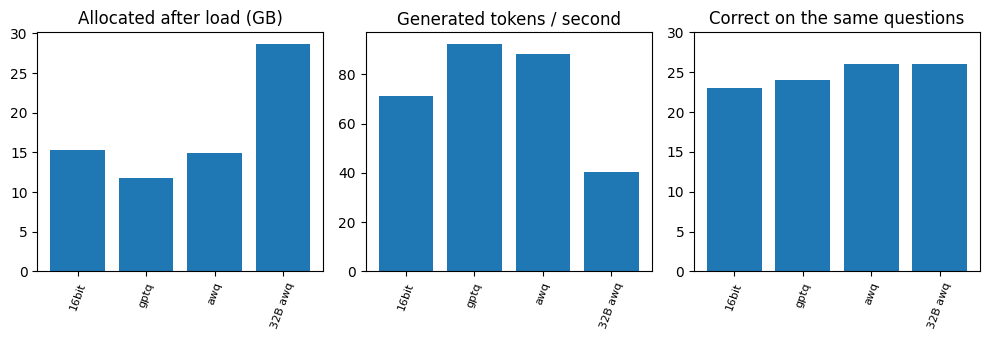

In [63]:
import numpy as np
import matplotlib.pyplot as plt
valid=[(name,row) for name,row in results.items() if isinstance(row,dict) and "correct" in row]
if valid:
    names=[name for name,row in valid]
    fig,axes=plt.subplots(1,3,figsize=(10,3.5))
    for ax,key,label in [(axes[0],"weights_gb","Allocated after load (GB)"),(axes[1],"tps","Generated tokens / second")]:
        ax.bar(range(len(valid)),[row.get(key,np.nan) for name,row in valid])
        ax.set(xticks=range(len(valid)),xticklabels=names,title=label)
        ax.tick_params(axis="x",rotation=70,labelsize=8)
    axes[2].bar(range(len(valid)),[sum(row["correct"].values()) for name,row in valid])
    axes[2].set(xticks=range(len(valid)),xticklabels=names,title="Correct on the same questions",ylim=(0,len(QUESTIONS)))
    axes[2].tick_params(axis="x",rotation=70,labelsize=8)
    fig.tight_layout();fig.savefig(WORK/"comparison.png",dpi=85);plt.show()

## Step 8. 선택 심화 트랙

두 트랙 중 **팀이 하나 이상 골라** 수행하고 공유합니다. 트랙도 GPU를 쓰므로 한 번에 하나씩 실행합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | 보정 데이터의 언어 : 영어 위키와 한국어 사내 문서 | 측정 | 중 |
| 2 | 보정 데이터의 개수와 만드는 시간 | 측정 | 중 |

</div>

#### 트랙 1. 보정 데이터의 언어

같은 7B를 영어 위키 문장으로 보정한 GPTQ 파일을 하나 더 만들어 한국어 보정 파일과 비교합니다(이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’).

In [64]:
from datasets import load_dataset

# 실습 : 긴 글을 토큰 length개씩 잘라 n개의 문자열로 반환하는 cut_chunks를 완성하세요
def cut_chunks(tok, text, n, length):
    ids = tok(text, add_special_tokens=False)["input_ids"]
    ### START CODE HERE ### (토큰 ID 를 length 개씩 끊어 글자로 되돌리기 1줄)
    # 1) ids 를 length 개씩 끊고(모자란 마지막 청크는 버림) 청크마다 tok.decode 로 글자로 되돌린 뒤 앞의 n 개만 남깁니다
    chunks = [tok.decode(ids[i:i + length]) for i in range(0, len(ids) - length + 1, length)][:n]
    ### END CODE HERE ###
    return chunks


def english_calibration(n, length):
    """영어 위키 문장(wikitext-2)을 이어 붙여 자릅니다. 받지 못하면 이유를 알리고 빈 목록을 반환합니다"""
    try:
        ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    except Exception as e:
        print(f"영어 보정 데이터를 받지 못했습니다 : {first_line(e)}")
        return []
    text = "\n".join(t for t in ds["text"] if len(t.strip()) > 40)
    # 영어는 토큰 하나가 대략 네다섯 글자라 필요한 양의 두 배쯤만 잘라 토큰으로 바꿉니다
    return cut_chunks(tok_base, text[: n * length * 8], n, length) or []


calib_en = english_calibration(N_CALIB, CALIB_TOKENS)
print(f"영어 청크 {len(calib_en)}개")
if calib_en:
    print(calib_en[0][:200])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

영어 청크 128개
 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ p


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
chunks = [tok.decode(ids[i:i + length]) for i in range(0, len(ids) - length + 1, length)][:n]
```

토큰 단위로 자르면 청크의 길이가 정확히 같아집니다.

</details>

In [65]:
EN_DIR = WORK / "7b-gptq-en"
if len(calib_en) < N_CALIB:
    print("영어 청크가 모자랍니다. 실습 셀을 채웠는지, 데이터를 받았는지 보세요")
else:
    print("겹친 평가 질문 :", leaked(calib_en))
    info_en = make_quant(qcfg_gptq, calib_en, EN_DIR)
    print(info_en)
    if "error" not in info_en:
        measure_file("gptq 영어", EN_DIR, "16bit", ref_repo=MODEL_ID)
        display(type_table(["16bit", "gptq", "gptq 영어"]))
        for n in ["gptq", "gptq 영어"]:
            if base_of(n):
                print(n, "flip", count_flips(results["16bit"]["correct"], results[n]["correct"]))

겹친 평가 질문 : []


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/workspace/hf/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.05,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  Packing Kernel: selected: `TorchLinear`                    

Writing model shards: 0it [00:00, ?it/s]

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "gptq",
  "quant_method": "gptq",
  "format": "gptq",
  "checkpoint_format": "gptq",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.5.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": 0.05,
    "damp_auto_increment": 0.01,
    "static_groups": false,
    "true_sequential": true,
    "mse": 0.0,
    "gptaq": null,
    "foem": null,
    "act_group_aware": true,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_26_l2dps",
    "pack_impl": "cpu",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_vr

Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7933 objects in 0.303s                             
  [언로드] GPU 메모리 11.79 -> 6.23 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[gptq 영어] 정답 24/30 | 첫 토큰 0.05 s (입력 803 토큰) | 초당 91.4 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'MarlinLinear': 196, 'Linear': 1}


,계산,분류,지문,형식
16bit,4/8,5/7,7/8,7/7
gptq,5/8,5/7,7/8,7/7
gptq 영어,5/8,4/7,8/8,7/7


gptq flip {'맞→틀': 0, '틀→맞': 1}
gptq 영어 flip {'맞→틀': 1, '틀→맞': 2}


**읽는 법**

- **유형별 열에서 달라진 곳을 봅니다.** 지문 질문은 한국어 규정 문장을 읽고 숫자를 찾는 질문이라 보정 언어의 영향이 먼저 드러날 수 있는 열입니다

#### 트랙 2. 보정 데이터의 개수

이론 노트 2장 심화 ‘보정 데이터의 크기’의 곡선을 그립니다. Step 3의 생성기로 32개와 256개를 더 만들어 128개와 함께 만드는 시간과 정답 수를 봅니다. 7B를 두 번 더 양자화하므로 시간이 넉넉할 때 합니다.

In [66]:
# 실습 : 개수마다 보정 청크를 만들어 GPTQ 파일을 만들고 측정하세요
#        128개는 Step 4에서 만든 GPTQ_DIR을 그대로 씁니다
SIZES = [32, 128, 256]
size_rows = []
for n in SIZES:
    if n == len(calib_ko):
        folder, name = GPTQ_DIR, "gptq"
    else:
        ### START CODE HERE ### (Step 3의 생성기로 보정 청크 n개 만들기 1줄)
        # 1) make_doc 을 Step 3과 같은 시드 1000번부터 n번 호출해 글(반환값의 두 번째 값)만 모읍니다
        calib_n = [make_doc(1000 + i, CALIB_TOKENS)[1] for i in range(n)]
        ### END CODE HERE ###
        if calib_n is None:
            size_rows = None
            break
        print(f"{n}개 : 겹친 평가 질문 {leaked(calib_n)}")
        folder, name = WORK / f"7b-gptq-ko-{n}", f"gptq {n}개"
        info = make_quant(qcfg_gptq, calib_n, folder)
        if "error" in info:
            print(n, info["error"])
            continue
        measure_file(name, folder, "16bit", ref_repo=MODEL_ID)
    info = json.loads((folder / "make_info.json").read_text(encoding="utf-8"))
    r = results.get(name, {})
    flips = count_flips(results["16bit"]["correct"], r["correct"]) if base_of(name) else {}
    size_rows.append({"n": n, "minutes": info.get("minutes"),
                      "correct": sum(r["correct"].values()) if "correct" in r else None,
                      "맞→틀": flips.get("맞→틀")})

if size_rows is None:
    print("size_rows가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    display(pd.DataFrame(size_rows).set_index("n"))

32개 : 겹친 평가 질문 []


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  Loader: using checkpoint-backed lazy turtle source for `/workspace/hf/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28`
INFO  Model: Loaded `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "eos_token_id": 151645,
  "output_attentions": false,
  "output_hidden_states": false,
  "pad_token_id": 151643,
  "use_cache": true
}

INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.05,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

INFO  Kernel: loaded -> `[]`                                                    
INFO  Packing Kernel: selected: `TorchLinear`                    

Writing model shards: 0it [00:00, ?it/s]

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "gptq",
  "quant_method": "gptq",
  "format": "gptq",
  "checkpoint_format": "gptq",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.5.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": 0.05,
    "damp_auto_increment": 0.01,
    "static_groups": false,
    "true_sequential": true,
    "mse": 0.0,
    "gptaq": null,
    "foem": null,
    "act_group_aware": true,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_26_l2dps",
    "pack_impl": "cpu",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_vr

... (6 outputs left out)

INFO  Saved Quantize Config: 
{
  "bits": 4,
  "group_size": 128,
  "desc_act": false,
  "lm_head": false,
  "method": "gptq",
  "quant_method": "gptq",
  "format": "gptq",
  "checkpoint_format": "gptq",
  "pack_dtype": "int32",
  "meta": {
    "quantizer": [
      "gptqmodel:7.5.0"
    ],
    "uri": "https://github.com/modelcloud/gptqmodel",
    "damp_percent": 0.05,
    "damp_auto_increment": 0.01,
    "static_groups": false,
    "true_sequential": true,
    "mse": 0.0,
    "gptaq": null,
    "foem": null,
    "act_group_aware": true,
    "fallback": {
      "strategy": "rtn",
      "threshold": "0.5%",
      "smooth": null
    },
    "offload_to_disk": true,
    "telemetry": {
      "device": false
    },
    "offload_to_disk_path": "/tmp/gptqmodel_26_l2dps",
    "pack_impl": "cpu",
    "gc_mode": "interval",
    "wait_for_submodule_finalizers": false,
    "auto_forward_data_parallel": true,
    "dense_vram_strategy": "exclusive",
    "dense_vram_strategy_devices": null,
    "moe_vr

Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7933 objects in 0.316s                             
  [언로드] GPU 메모리 12.30 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[gptq 256개] 정답 24/30 | 첫 토큰 0.05 s (입력 803 토큰) | 초당 91.6 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'MarlinLinear': 196, 'Linear': 1}


,minutes,correct,맞→틀
n,,,
32,2.8,23,0
128,3.3,24,0
256,4.1,24,1


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
calib_n = [make_doc(1000 + i, CALIB_TOKENS)[1] for i in range(n)]
```

**시간은 개수에 비례해 늘고 정답 수는 어디선가 멈춥니다.**

</details>

## Step 9. 공유와 정리

팀 결과를 정리하고 다른 팀의 결과와 나란히 놓습니다.

**1. 역할표와 시간** : 역할표의 이름 칸과 실행 환경 표의 걸린 시간 칸을 채웁니다

**2. 비교표** : Step 7의 표에서 GPU 이름, 커널 이름, 첫 토큰 시간, 초당 토큰. 두 팀의 표를 나란히 놓고 같은 행의 수치가 다르면 GPU, 커널, 측정 변동 가운데 무엇 때문인지 한 문단으로 적습니다

**3. 만드는 비용** : 7B를 GPTQ와 AWQ로 만드는 데 걸린 시간과 GPU·시스템 메모리 최고점

**4. 세 기법과 32B** : 세 기법 비교표에서 고른 기법과 근거, 32B 4비트와 7B 16비트 가운데 고른 쪽과 근거

**5. 선택한 트랙의 결과** : 얻은 판단 하나와 판단을 뒷받침한 수치

4비트를 **로드할 때 바꾸는 설정에서 미리 만들어 두는 파일로** 옮겼고 32B를 GPU 한 장에 올렸습니다. 다음 날 vLLM 기초 노트에서 같은 볼륨의 파일을 서빙합니다.

#### Pod 종료 점검표

하루가 끝나면 **Pod를 종료(terminate)하고 볼륨만 남깁니다.** Pod를 종료해도 네트워크 볼륨의 데이터는 남고 컨테이너 디스크는 지워집니다. 부록 실습을 한다면 부록을 마친 뒤 이 점검표를 실행합니다.

1. 아래 셀로 결과 파일과 4비트 폴더가 `/workspace` 아래에 있는지 확인합니다  
2. 결과 파일(`d56_results.json`, `d56_results.csv`, `three_methods.csv`)을 팀 제출물로 내려받아 둡니다  
3. 실행 중인 셀을 멈춥니다  
4. RunPod 콘솔에서 Pod를 종료합니다. 볼륨은 지우지 않습니다  
5. Pod가 목록에서 사라졌는지와 볼륨이 남아 있는지 확인하고 오늘 Pod를 쓴 시간을 적어 RunPod 요금표로 비용을 확인합니다

다음 날 vLLM 기초 노트는 같은 볼륨을 붙여 새 Pod를 만들고 시작합니다. 컨테이너 디스크에 설치한 패키지와 GPTQModel의 컴파일 캐시는 사라지므로 설치부터 다시 실행합니다.

In [67]:
# 볼륨에 남을 것을 확인합니다. 여기 없는 파일은 Pod를 종료하면 사라집니다
print(f"{WORK}")
for p in sorted(WORK.iterdir()):
    size = sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size
    print(f"  {p.name:<28} {size / 1e9:6.2f} GB")
print("볼륨에 저장된 행 :", list(json.loads(RESULT_FILE.read_text(encoding="utf-8"))) if RESULT_FILE.exists() else "없음")
print(f"볼륨 남은 디스크 : {shutil.disk_usage(WORK).free / 1e9:.0f} GB")

/workspace/results/d56
  7b-awq-ko                      5.58 GB
  7b-gptq-en                     5.59 GB
  7b-gptq-ko                     5.59 GB
  7b-gptq-ko-256                 5.59 GB
  7b-gptq-ko-32                  5.59 GB
  calib_ko.json                  0.00 GB
  comparison.png                 0.00 GB
  d56_results.csv                0.00 GB
  d56_results.json               0.00 GB
  d56_results_previous_1794296197871693274.json   0.00 GB
  d56_serving_handoff.json       0.00 GB
  three_methods.csv              0.00 GB
볼륨에 저장된 행 : ['16bit', 'nf4', 'gptq', 'awq', '32B awq', 'gptq 영어', 'gptq 32개', 'gptq 256개', '_conditions']
볼륨 남은 디스크 : 181 GB


### 혼자 설명하기

같은 7B 원본으로 만든 GPTQ·AWQ 모델 중 다음 날 서버로 실행할 모델을 고릅니다. 보정 입력과 평가 질문을 분리했는지, 어떤 답이 달라졌는지, 어떤 구현으로 실행됐는지, 필요한 파일이 모두 저장됐는지를 확인해 선택 이유를 설명합니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D57에서는 직접 만든 7B 모델 파일로 서버를 실행합니다. 별도로 32B 4비트 모델의 메모리·입력 길이·동시 요청 설정도 비교합니다.

## 마무리 과제. 4비트 배포 판단서

여러분이 가정한 사내 서비스에 배포할 4비트 파일을 고르고 판단서를 씁니다.

**1단계. 고르는 순서**

1. 이론 노트 5.3절의 순서대로 라이선스, 실행 도구, 커널을 먼저 적습니다  
2. 받을지 만들지 정합니다. 만든다면 누가 어떤 GPU에서 만드는지와 Step 4에서 측정한 시간을 근거로 듭니다. 32B 공식 파일과 7B 직접 만든 파일 가운데 무엇을 쓸지도 Step 7의 표로 정합니다

**2단계. 보정 데이터**

3. 실제로 넣을 문서 종류와 개수, 청크의 평균 토큰 수를 정합니다  
4. 평가 질문을 만들 문서와 보정 데이터를 뽑을 문서를 나누고 Step 3의 겹침 검사 결과를 적습니다

**3단계. 측정**

5. 여러분 업무의 질문을 종류별로 나눠 40개 이상 만듭니다  
6. 원본(또는 bitsandbytes 4비트)과 후보 파일 둘 이상을 Step 7의 표로 측정합니다. 커널 이름과 입력 길이를 수치 옆에 적습니다  
7. 정오답이 달라진 문항을 직접 읽고 무엇이 망가졌는지 한 줄씩 적습니다

**4단계. 기록**

8. 고른 파일의 모델 카드를 부록 실습 C의 형식으로 씁니다  
9. 다시 측정할 날을 적습니다. 실행 도구나 GPU 세대를 바꾸는 날입니다(이론 노트 5.3절 퀴즈)

**평가 기준**

고른 형식이 아니라 **근거와 재현**으로 평가합니다.

보정 데이터와 평가 질문이 겹치지 않았다는 확인이 빠진 판단서는 통과하지 않습니다.

## 부록 실습 A. 층마다 남은 오차와 컴파일 캐시

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 본 실습 Step 5까지 실행한 상태에서 시작합니다. Pod 종료 점검표는 부록을 마친 뒤 실행합니다.

Step 4와 Step 5에서 만든 폴더의 `quant_log.csv`로 층마다 남은 오차를 읽고 두 번째 로드로 커널 컴파일 캐시를 확인합니다(이론 노트 4.2절, 4장 심화 ‘GPTQModel’).

기록 196행 / 숫자가 아닌 오차 0행
  q_proj     평균 0.000122  최대 0.000505
  v_proj     평균 0.000048  최대 0.000411
  k_proj     평균 0.000019  최대 0.000056
  o_proj     평균 0.000025  최대 0.000165
  gate_proj  평균 0.000636  최대 0.002022
  up_proj    평균 0.000599  최대 0.002120
  down_proj  평균 0.000347  최대 0.005971


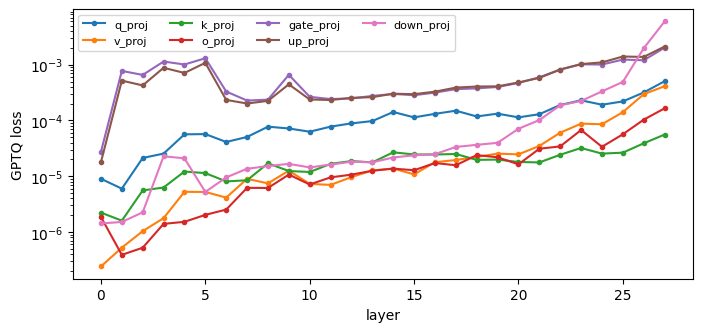

In [68]:
import matplotlib.pyplot as plt


def read_quant_log(folder):
    """quant_log.csv에서 층 번호, 모듈 이름, 오차를 읽습니다.
    GPTQModel 7.5.0의 이 파일은 헤더 행의 열 이름이 6개인데 값은 5개 열만 적혀 이름과 값이 어긋납니다.
    그래서 열 이름으로 읽지 않고 층, 모듈, 오차 세 열을 순서대로 읽습니다"""
    rows = []
    with open(Path(folder) / "quant_log.csv", encoding="utf-8") as f:
        reader = csv.reader(f)
        next(reader, None)
        for cells in reader:
            if len(cells) < 3:
                continue
            try:
                loss = float(cells[2])
            except ValueError:
                loss = None                 # fallback이나 not applicable 같은 글자
            rows.append({"layer": int(cells[0]), "module": cells[1], "loss": loss, "text": cells[2]})
    return rows


qlog = read_quant_log(GPTQ_DIR) if (GPTQ_DIR / "quant_log.csv").exists() else []
print(f"기록 {len(qlog)}행 / 숫자가 아닌 오차 {sum(r['loss'] is None for r in qlog)}행")
by_module = {}
for r in qlog:
    if r["loss"] is not None:
        by_module.setdefault(r["module"].split(".")[-1], []).append(r)
for name, rs in by_module.items():
    vals = [r["loss"] for r in rs]
    print(f"  {name:<10} 평균 {sum(vals) / len(vals):.6f}  최대 {max(vals):.6f}")

if by_module:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for name, rs in by_module.items():
        ax.plot([r["layer"] for r in rs], [r["loss"] for r in rs], marker=".", label=name)
    ax.set_yscale("log")
    ax.set_xlabel("layer")
    ax.set_ylabel("GPTQ loss")
    ax.legend(ncol=4, fontsize=8)
    plt.show()

**층마다 남은 오차를 읽는 법**

- **같은 모듈끼리 층을 따라 비교합니다.**  
- **튀는 층을 찾습니다.**  
- **숫자가 아닌 오차를 셉니다.** fallback이 기록된 행은 보정 입력이 모자라 그냥 반올림으로 대신한 모듈입니다(이론 노트 4장 심화 ‘GPTQModel’)

In [69]:
# 실습 : 오차가 가장 큰 모듈 다섯 개를 고르세요
### START CODE HERE ### (qlog 에서 오차가 큰 모듈 다섯 개 고르기 2줄)
# 1) 숫자가 아닌 오차(None)는 빼고 오차(loss)가 큰 순서로 정렬해 앞의 다섯 개를 남깁니다
worst = sorted((r for r in qlog if r["loss"] is not None),
               key=lambda r: r["loss"], reverse=True)[:5]
### END CODE HERE ###

if worst is None:
    print("worst가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    for r in worst:
        print(f"  층 {r['layer']:>2}  {r['module']:<18} {r['loss']:.6f}")

  층 27  mlp.down_proj      0.005971
  층 27  mlp.up_proj        0.002120
  층 27  mlp.gate_proj      0.002022
  층 26  mlp.down_proj      0.001972
  층 25  mlp.up_proj        0.001404


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
worst = sorted((r for r in qlog if r["loss"] is not None),
               key=lambda r: r["loss"], reverse=True)[:5]
```

다섯 개가 한 모듈 종류에 몰려 있는지, 한 층에 몰려 있는지를 봅니다. 그림에서 같은 모듈의 다른 층보다 튀었는지를 함께 봐야 판단이 섭니다.

</details>

In [70]:
alog = read_quant_log(AWQ_DIR) if (AWQ_DIR / "quant_log.csv").exists() else []
na = sorted({r["module"] for r in alog if r["loss"] is None})
print(f"숫자가 아닌 오차 {sum(r['loss'] is None for r in alog)}행 : {na}")
print("층 0의 q, k, v 오차 :", [(r["module"], r["text"]) for r in alog
                              if r["layer"] == 0 and r["module"].endswith(("q_proj", "k_proj", "v_proj"))])

숫자가 아닌 오차 28행 : ['self_attn.o_proj']
층 0의 q, k, v 오차 : [('self_attn.q_proj', '0.0000547918'), ('self_attn.k_proj', '0.0000547918'), ('self_attn.v_proj', '0.0000547918')]


**AWQ 기록이 GPTQ와 다른 점**

- **q, k, v의 오차가 같은 값입니다.** 세 모듈이 같은 입력을 받아 키울 배수 하나를 함께 고르기 때문입니다  
- **o_proj 행에는 not applicable이 기록됩니다.**  
- **GPTQ의 오차와 비교하지 않습니다.** 두 방법이 오차를 서로 다르게 셉니다

In [71]:
# 두 번째 로드. 컴파일한 커널을 캐시에서 읽으므로 짧아져야 합니다
h = load_model(str(GPTQ_DIR), "16bit")
if "error" in h:
    print("로드 실패 :", h["error"])
else:
    print(f"두 번째 로드 {h['load_sec']:.1f} s / 첫 로드 {results.get('gptq', {}).get('load_sec', 0):.1f} s")
    print("선형 층 :", describe_layers(h["model"])["선형 층"])
    unload(h)
ext = Path.home() / ".cache" / "gptqmodel" / "torch_extensions"
print("컴파일 캐시 :", sorted(p.name for p in ext.iterdir() if p.is_dir()) if ext.exists() else "없음")

INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       


Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7933 objects in 0.319s                             
두 번째 로드 1.2 s / 첫 로드 1.3 s
선형 층 : {'MarlinLinear': 196, 'Linear': 1}
  [언로드] GPU 메모리 12.30 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
컴파일 캐시 : ['awq', 'marlin_fp16', 'pack_block_cpu']


**로컬 작업** : 사내 서버라면 서버 이미지를 만들 때 이 셀까지 실행해 캐시를 이미지에 넣어 둡니다. RunPod에서는 홈 폴더가 컨테이너 디스크라 Pod를 새로 기동하면 캐시가 사라집니다.

## 부록 실습 B. 7B 공식 파일과 직접 만든 파일

Qwen 팀이 업로드한 7B GPTQ 4비트 파일과 AWQ 파일을 받아 Step 4와 Step 5에서 한국어로 보정해 직접 만든 파일과 비교합니다(이론 노트 1.4절). 두 파일을 합쳐 11GB 남짓을 볼륨에 더 받습니다.

In [72]:
REPO_7B_GPTQ = os.environ.get("D56_7B_GPTQ", "Qwen/Qwen2.5-7B-Instruct-GPTQ-Int4")
REPO_7B_AWQ = os.environ.get("D56_7B_AWQ", "Qwen/Qwen2.5-7B-Instruct-AWQ")
for repo in [REPO_7B_GPTQ, REPO_7B_AWQ]:
    qc = getattr(AutoConfig.from_pretrained(repo), "quantization_config", None) or {}
    keys = ["quant_method", "bits", "group_size", "sym", "desc_act", "version", "zero_point"]
    print(repo, {k: qc[k] for k in keys if k in qc})

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct-GPTQ-Int4 {'quant_method': 'gptq', 'bits': 4, 'group_size': 128, 'sym': True, 'desc_act': False}


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct-AWQ {'quant_method': 'awq', 'bits': 4, 'group_size': 128, 'version': 'gemm', 'zero_point': True}


In [73]:
measure_file("7B gptq", REPO_7B_GPTQ, "16bit", ref_repo=MODEL_ID)
measure_file("7B awq", REPO_7B_AWQ, "16bit", ref_repo=MODEL_ID)
display(overview())

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/75.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (13 outputs left out)

Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

INFO  gc.collect() reclaimed 6334 objects in 0.335s                             
  [언로드] GPU 메모리 12.32 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
[7B awq] 정답 25/30 | 첫 토큰 0.047 s (입력 803 토큰) | 초당 88.1 토큰 | 생성 설정 바뀐 값 {}
  선형 층 : {'AwqMarlinLinear': 196, 'Linear': 1}


,잰 곳,디스크 GB,올린 직후 GB,최고점 GB,첫 토큰 s,초당 토큰,PPL비 한,1순위 한,정답,맞→틀,틀→맞,선형 층
이름,,,,,,,,,,,,
16bit,D56,15.23,15.27,16.01,0.044,71.3,-,-,23/30,-,-,Linear 197
nf4,-,-,-,-,-,-,-,-,-,-,-,실패 : ImportError: Using `bitsandbytes` 4-bit q...
gptq,D56,5.58,11.79,12.53,0.05,92.4,1.033,92.6%,24/30,0.0,1.0,"MarlinLinear 196, Linear 1"
awq,D56,5.57,14.96,15.7,0.047,88.3,1.011,92.8%,26/30,0.0,3.0,"AwqMarlinLinear 196, Linear 1"
32B awq,D56,19.33,28.69,29.44,0.186,40.4,0.765,80.0%,26/30,1.0,4.0,"AwqMarlinLinear 448, Linear 1"
gptq 영어,D56,5.58,11.79,12.53,0.05,91.4,1.063,91.2%,24/30,1.0,2.0,"MarlinLinear 196, Linear 1"
gptq 32개,D56,5.58,11.44,12.18,0.051,90.9,1.023,93.1%,23/30,0.0,0.0,"MarlinLinear 196, Linear 1"
gptq 256개,D56,5.58,12.3,13.04,0.05,91.6,1.021,93.1%,24/30,1.0,2.0,"MarlinLinear 196, Linear 1"
7B gptq,D56,-,12.3,13.04,0.049,91.3,1.042,92.8%,24/30,0.0,1.0,"MarlinLinear 196, Linear 1"


**선형 층과 정답 열을 비교합니다.** 공식 파일은 어떤 보정 데이터로 만들었는지 알 수 없습니다. 한국어로 보정한 `gptq`, `awq` 행과 공식 `7B gptq`, `7B awq` 행의 정답 수와 정오답이 달라진 문항이 다르다면 보정 데이터의 차이일 수 있습니다(이론 노트 3장 심화 ‘보정 데이터의 언어와 내용’). 비교가 끝났고 볼륨이 모자라면 아래 셀로 공식 7B 파일만 지웁니다.

In [74]:
from huggingface_hub import scan_cache_dir


def drop_cache(repo_id):
    """허깅페이스 캐시에서 저장소 하나를 지웁니다. 디스크가 모자랄 때만 호출합니다"""
    try:
        info = scan_cache_dir()
    except Exception as e:
        return f"캐시를 읽지 못함 : {first_line(e)}"
    hashes = [rev.commit_hash for r in info.repos if r.repo_id == repo_id for rev in r.revisions]
    if not hashes:
        return f"{repo_id} : 캐시에 없음"
    plan = info.delete_revisions(*hashes)
    plan.execute()
    return f"{repo_id} : {plan.expected_freed_size / 1e9:.1f} GB 지움"


free_gb = shutil.disk_usage(WORK).free / 1e9
print(f"볼륨 남은 디스크 {free_gb:.0f} GB")
if free_gb < 15:
    for repo in [REPO_7B_GPTQ, REPO_7B_AWQ]:    # 32B AWQ와 7B 원본은 다음 날 쓰므로 지우지 않습니다
        print(drop_cache(repo))

볼륨 남은 디스크 170 GB


## 부록 실습 C. 모델 카드 세부

직접 만든 두 파일의 폴더에 이론 노트 5.3절의 항목을 적은 `README.md`를 남깁니다. 마무리 과제의 모델 카드를 이 형식으로 씁니다. vLLM 기초 노트에서 이 폴더를 서빙할 때 카드가 함께 갑니다.

In [75]:
from huggingface_hub import model_info


def license_of(repo):
    """원본 저장소의 라이선스 이름을 읽습니다. 읽지 못하면 확인 못 함이라고 적습니다"""
    try:
        card = model_info(repo).card_data or {}
        return card.get("license_name") or card.get("license") or "확인 못 함"
    except Exception:
        return "확인 못 함 (원본 저장소의 LICENSE를 직접 확인하세요)"


def write_card(folder, name):
    folder = Path(folder)
    info_file = folder / "make_info.json"
    info = json.loads(info_file.read_text(encoding="utf-8")) if info_file.exists() else {}
    r = results.get(name, {})
    if "correct" not in r:
        return f"{name} : 측정 결과가 없어 카드를 쓰지 않습니다"
    b = base_of(name)
    flips = count_flips(results[b]["correct"], r["correct"]) if b else "기준선 없음"
    lines = [
        f"# {name}", "",
        f"- 원본 : {MODEL_ID} / 라이선스 : {license_of(MODEL_ID)} (확인일 {time.strftime('%Y-%m-%d')})",
        f"- 알고리즘과 설정 : {info.get('method')}, {info.get('bits')}비트, 그룹 {info.get('group_size')}, "
        f"대칭 {info.get('sym')}",
        f"- 만든 도구 : GPTQModel {info.get('gptqmodel')} / {info.get('gpu')} / {info.get('minutes')}분 / "
        f"GPU 최고점 {info.get('gpu_peak_gb')} GB",
        f"- 보정 데이터 : {CALIB_CARD['source']} / {CALIB_CARD['count']}개 / 평균 {CALIB_CARD['avg_tokens']}토큰 / "
        f"평가 질문과 겹침 {CALIB_CARD['leak_hits']}",
        f"- 측정 조건 : 양자화 노트의 벤치마크 하네스 / transformers {pkgver('transformers')} / "
        f"{torch.cuda.get_device_name(0) if HAS_GPU else 'CPU'} / {str(DTYPE16).replace('torch.', '')} / "
        f"선형 층 {r['layers']['선형 층']}",
        f"- 결과 : 디스크 {r.get('disk_gb')} GB, 로드 직후 {gb(r.get('weights_gb'))} GB, 첫 토큰 {r.get('ttft_s')} s "
        f"(입력 {r.get('input_tokens')} 토큰), 초당 {round(r['tps'], 1)} 토큰, "
        f"정답 {sum(r['correct'].values())}/{len(QUESTIONS)}, 16비트 대비 flip {flips}",
    ]
    (folder / "README.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    return "\n".join(lines)


for folder, name in [(GPTQ_DIR, "gptq"), (AWQ_DIR, "awq")]:
    if folder.exists():
        print(write_card(folder, name), "\n")

# gptq

- 원본 : Qwen/Qwen2.5-7B-Instruct / 라이선스 : apache-2.0 (확인일 2026-11-10)
- 알고리즘과 설정 : GPTQConfig, 4비트, 그룹 128, 대칭 True
- 만든 도구 : GPTQModel 7.5.0 / NVIDIA RTX PRO 6000 Blackwell Server Edition / 3.3분 / GPU 최고점 8.62 GB
- 보정 데이터 : 규칙으로 지어낸 한국어 사내 문서 (규정, 회의록, 공지, 매뉴얼, 보고서, 메일) / 128개 / 평균 532토큰 / 평가 질문과 겹침 []
- 측정 조건 : 양자화 노트의 벤치마크 하네스 / transformers 5.22.1 / NVIDIA RTX PRO 6000 Blackwell Server Edition / float16 / 선형 층 {'MarlinLinear': 196, 'Linear': 1}
- 결과 : 디스크 5.58 GB, 로드 직후 11.79 GB, 첫 토큰 0.05 s (입력 803 토큰), 초당 92.4 토큰, 정답 24/30, 16비트 대비 flip {'맞→틀': 0, '틀→맞': 1} 

# awq

- 원본 : Qwen/Qwen2.5-7B-Instruct / 라이선스 : apache-2.0 (확인일 2026-11-10)
- 알고리즘과 설정 : AWQConfig, 4비트, 그룹 128, 대칭 False
- 만든 도구 : GPTQModel 7.5.0 / NVIDIA RTX PRO 6000 Blackwell Server Edition / 3.9분 / GPU 최고점 15.16 GB
- 보정 데이터 : 규칙으로 지어낸 한국어 사내 문서 (규정, 회의록, 공지, 매뉴얼, 보고서, 메일) / 128개 / 평균 532토큰 / 평가 질문과 겹침 []
- 측정 조건 : 양자화 노트의 벤치마크 하네스 / transformers 5.22.1 / NVIDIA RTX PRO 6000 Blackwell Server Edition / float16 / 선

카드의 라이선스 줄에 원본과 같은 apache-2.0이 기록되었는지 봅니다.

## 부록 실습 D. QLoRA 병합본의 GPTQ 양자화

QLoRA 병합본을 보정 데이터로 양자화해 GPTQ 파일로 만들고 회의록 양식을 지키는 비율을 16비트 병합본과 비교합니다. QLoRA 실습의 병합본이나 어댑터 폴더를 볼륨의 `/workspace/qlora/`에 올려 두고 시작합니다.

**이 트랙의 파일은 평가용입니다.** 병합본의 베이스가 Qwen2.5-3B-Instruct라 병합본과 그 GPTQ 파일도 Qwen Research License를 따릅니다(이론 노트 1.6절).

In [76]:
!PIP_CACHE_DIR=/workspace/pip-cache pip install -q "peft>=0.21,<0.22"

In [77]:
from peft import PeftModel

QLORA_BASE = os.environ.get("D56_QLORA_BASE", "Qwen/Qwen2.5-3B-Instruct")     # QLoRA 실습의 베이스
# QLoRA 실습의 결과 폴더를 볼륨에 올려 둔 곳입니다
MERGED_DIR = Path(os.environ.get("D56_MERGED_DIR", "/workspace/qlora/merged_model"))
ADAPTER_DIR = Path(os.environ.get("D56_ADAPTER_DIR", "/workspace/qlora/qlora_adapter"))
MERGED_GPTQ = WORK / "merged-gptq"

# QLoRA 실습이 학습에 쓴 문장 그대로입니다. 학습과 다른 프롬프트로 측정하면 양자화의 효과와 프롬프트의 효과가 섞입니다
QLORA_SYSTEM = ("당신은 사내 문서를 정리하는 어시스턴트입니다. "
                "답변은 반드시 한국어로 작성합니다.")
INSTRUCTION = "다음 회의록 원문을 사내 표준 양식으로 정리하세요."
REQUIRED_SECTIONS = ["## 회의 개요", "## 결정 사항", "## 논의 사항", "## 후속 조치"]

# QLoRA 노트 코드 Step 2의 생성기와 같은 내용입니다. Step 3의 이름과 겹치지 않게 이름 앞에 M_만 붙였습니다
M_TOPICS = ["신규 기능 출시", "인프라 비용 절감", "채용 계획", "보안 감사 대응",
            "고객 이슈 처리", "분기 실적 검토", "협력사 계약", "교육 프로그램 개편"]
M_PEOPLE = ["김서준", "이지우", "박민재", "최유나", "정하윤", "강도현", "윤서아", "임태호"]
M_TEAMS = ["개발1팀", "개발2팀", "인프라팀", "기획팀", "영업팀", "보안팀", "인사팀"]
M_ACTIONS = ["일정을 확정했다", "예산을 승인했다", "담당을 지정했다", "보류하기로 했다",
             "추가 검토가 필요하다는 의견이 나왔다", "다음 회의에서 재논의하기로 했다"]


def make_raw_minutes(seed):
    rnd = random.Random(seed)
    topic = rnd.choice(M_TOPICS)
    attendees = rnd.sample(M_PEOPLE, rnd.randint(3, 5))
    month, day = rnd.randint(1, 12), rnd.randint(1, 28)
    lines = [f"{month}월 {day}일 {topic} 관련 회의. 참석자 {', '.join(attendees)}."]
    n_items = rnd.randint(2, 4)
    decided, discussed = [], []
    for i in range(n_items):
        act = rnd.choice(M_ACTIONS)
        owner = rnd.choice(attendees)
        team = rnd.choice(M_TEAMS)
        if "보류" in act or "검토" in act or "재논의" in act:
            lines.append(f"- {topic} 관련 {i+1}번 안건은 {act}. {team} 의견 수렴 필요.")
            discussed.append((f"{topic} {i+1}번 안건", act))
        else:
            deadline = f"{month+1 if month < 12 else 1}월 {rnd.randint(1,28)}일"
            lines.append(f"- {i+1}번 안건 {act}. {owner}이 {deadline}까지 진행.")
            decided.append((f"{i+1}번 안건 {act}", owner, deadline))
    if rnd.random() < 0.5:
        lines.append(f"- 다음 회의는 {month+1 if month < 12 else 1}월 {rnd.randint(1,28)}일.")
    return {"raw": "\n".join(lines),
            "meta": {"date": f"{month}월 {day}일", "attendees": attendees,
                     "topic": topic, "decided": decided, "discussed": discussed}}


def make_gold_output(meta):
    lines = ["## 회의 개요", f"- 일시 : {meta['date']}", f"- 참석 : {', '.join(meta['attendees'])}",
             f"- 주제 : {meta['topic']}", "", "## 결정 사항"]
    if meta["decided"]:
        for i, (what, owner, when) in enumerate(meta["decided"], 1):
            lines.append(f"{i}. {what} / 담당: {owner} / 기한: {when}")
    else:
        lines.append("1. 없음 / 담당: 미정 / 기한: 미정")
    lines += ["", "## 논의 사항"]
    if meta["discussed"]:
        for what, act in meta["discussed"]:
            lines.append(f"- {what}: {act}")
    else:
        lines.append("- 없음")
    lines += ["", "## 후속 조치"]
    if meta["discussed"]:
        lines.append(f"- {meta['discussed'][0][0]} 재검토 및 의견 수렴")
    else:
        lines.append("- 결정 사항 이행 점검")
    return "\n".join(lines)


print(make_raw_minutes(20000)["raw"])

3월 19일 협력사 계약 관련 회의. 참석자 정하윤, 윤서아, 강도현, 최유나.
- 1번 안건 일정을 확정했다. 강도현이 4월 15일까지 진행.
- 협력사 계약 관련 2번 안건은 보류하기로 했다. 개발2팀 의견 수렴 필요.


In [78]:
# 실습 : 보정 청크를 실제로 받을 입력과 같은 대화 형식으로 만드세요
#        시드는 QLoRA 실습이 쓰지 않은 30000번부터 씁니다. 학습(0번대), 검증(10000번대), 테스트(20000번대)와 겹치지 않습니다
def minutes_calib(tok, n, start=30000):
    texts = []
    for i in range(start, start + n):
        m = make_raw_minutes(i)
        msgs = [{"role": "system", "content": QLORA_SYSTEM},
                {"role": "user", "content": f"{INSTRUCTION}\n\n{m['raw']}"},
                {"role": "assistant", "content": make_gold_output(m["meta"])}]
        ### START CODE HERE ### (대화 msgs 를 채팅 템플릿에 넣어 글자로 받기 1줄)
        # 1) 시스템 문장, 지시문과 원문, 정답 양식이 든 msgs 를 tok 의 채팅 템플릿에 넣고 토큰이 아닌 글자로 받습니다(tokenize=False)
        text = tok.apply_chat_template(msgs, tokenize=False)
        ### END CODE HERE ###
        texts.append(text)
    return texts


tok_qlora = AutoTokenizer.from_pretrained(QLORA_BASE)
calib_minutes = minutes_calib(tok_qlora, N_CALIB)
if any(t is None for t in calib_minutes):
    print("보정 청크가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    m_lens = [len(tok_qlora(t)["input_ids"]) for t in calib_minutes]
    print(f"회의록 보정 청크 {len(calib_minutes)}개 / 평균 {sum(m_lens) / len(m_lens):.0f} 토큰")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

회의록 보정 청크 128개 / 평균 372 토큰


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
text = tok.apply_chat_template(msgs, tokenize=False)
```

병합본이 서비스에서 받을 입력은 채팅 템플릿을 거친 대화입니다. **보정 청크도 같은 형식이어야** 각 층에 실제로 들어올 입력의 통계가 모입니다(이론 노트 2.3절).

</details>

In [79]:
def prepare_merged():
    """병합본 폴더를 준비합니다. 있으면 그대로 쓰고 없으면 어댑터로 만듭니다. 못 만들면 이유를 반환합니다"""
    if (MERGED_DIR / "config.json").exists():
        return None
    cfg_file = ADAPTER_DIR / "adapter_config.json"
    if not cfg_file.exists():
        return f"병합본도 어댑터도 없습니다 : {MERGED_DIR}, {ADAPTER_DIR}. QLoRA 실습의 결과 폴더를 복사해 오세요"
    base = json.loads(cfg_file.read_text(encoding="utf-8")).get("base_model_name_or_path")
    if base != QLORA_BASE:
        return f"어댑터의 베이스({base})가 QLORA_BASE({QLORA_BASE})와 다릅니다"
    h, merged = None, None
    try:
        h = load_model(QLORA_BASE, "16bit")
        if "error" in h:
            return h["error"]
        merged = PeftModel.from_pretrained(h["model"], str(ADAPTER_DIR)).merge_and_unload()
        merged.save_pretrained(str(MERGED_DIR))
        h["tok"].save_pretrained(str(MERGED_DIR))
    except Exception as e:
        return first_line(e)
    finally:
        merged = None
        if h is not None and "error" not in h:
            unload(h)
    return None


def minutes_score(path, n=20):
    """QLoRA 실습의 테스트 시드(20000번부터)로 양식을 지킨 비율을 셉니다.
    네 제목이 모두 있고 결정 사항의 담당자가 모두 적혀 있어야 통과입니다"""
    h = load_model(str(path), "16bit")
    if "error" in h:
        return {"error": h["error"]}
    passed = 0
    try:
        for i in range(20000, 20000 + n):
            m = make_raw_minutes(i)
            msgs = [{"role": "system", "content": QLORA_SYSTEM},
                    {"role": "user", "content": f"{INSTRUCTION}\n\n{m['raw']}"}]
            enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                               return_dict=True, return_tensors="pt")
            enc = {k: v.to(h["model"].device) for k, v in enc.items()}
            with torch.no_grad():
                out = h["model"].generate(**enc, max_new_tokens=300, do_sample=False,
                                          pad_token_id=h["tok"].pad_token_id)
            ans = h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)
            passed += all(s in ans for s in REQUIRED_SECTIONS) and all(o in ans for _, o, _ in m["meta"]["decided"])
        result = {"pass_rate": passed / n, "선형 층": describe_layers(h["model"])["선형 층"],
                  "올린 직후 GB": gb(h["weights_gb"])}
    except Exception as e:
        result = {"error": first_line(e)}
    finally:
        unload(h)
    return result


reason = prepare_merged()
if reason:
    print("부록 실습 D를 진행할 수 없습니다 :", reason)
elif any(t is None for t in calib_minutes):
    print("보정 청크가 비어 있습니다. 실습 셀을 먼저 채우세요")
else:
    print("병합본 GPTQ :", make_quant(qcfg_gptq, calib_minutes, MERGED_GPTQ, src=MERGED_DIR))
    for label, path in [("병합본 16비트", MERGED_DIR), ("병합본 GPTQ", MERGED_GPTQ)]:
        print(label, minutes_score(path))

부록 실습 D를 진행할 수 없습니다 : 병합본도 어댑터도 없습니다 : /workspace/qlora/merged_model, /workspace/qlora/qlora_adapter. QLoRA 실습의 결과 폴더를 복사해 오세요


**읽는 법** : 병합본 GPTQ의 비율이 16비트 병합본과 비슷하고 `올린 직후 GB`가 3분의 1 남짓이라면 이 GPTQ 파일이 배포 단위가 될 수 있습니다.

## 부록 실습 E. 입력 길이와 속도

입력의 문서 부분을 256, 1,000, 3,000 토큰으로 늘려 가며 7B 네 행(16비트, NF4, GPTQ, AWQ)의 첫 토큰 시간과 디코드 속도를 측정합니다.

In [80]:
LENGTHS = [256, 1000, 3000]


def long_prompt(n_tokens):
    """지어낸 사내 문서를 이어 붙여 n_tokens 토큰의 입력을 만듭니다"""
    text, i = "", 0
    while len(tok_base(text)["input_ids"]) < n_tokens:
        text += make_doc(5000 + i, 256)[1] + "\n"
        i += 1
    ids = tok_base(text, add_special_tokens=False)["input_ids"][:n_tokens]
    return tok_base.decode(ids) + "\n\n질문 : 이 문서들에서 날짜가 들어간 내용을 세 가지만 골라 설명하십시오."


PROMPTS = {n: long_prompt(n) for n in LENGTHS}
TARGETS = [("16bit", MODEL_ID, "16bit"), ("nf4", MODEL_ID, "nf4"),
           ("gptq", GPTQ_DIR, "16bit"), ("awq", AWQ_DIR, "16bit")]

# 실습 : TARGETS의 모델을 하네스의 load_model로 하나씩 로드해 align_generation으로 생성 설정을 맞추고
#        길이마다 split_speed(h, PROMPTS[n], n_new=64)를 측정한 뒤 unload로 언로드하세요
curve = {}
for name, path, precision in TARGETS:
    h = load_model(str(path), precision)
    if "error" in h:
        curve[name] = h["error"]
        continue
    try:
        ### START CODE HERE ### (생성 설정을 맞추고 길이마다 첫 토큰 시간과 속도 측정하기 2줄)
        # 1) 같은 크기 원본(MODEL_ID)의 생성 설정으로 맞춥니다
        align_generation(h, MODEL_ID)
        # 2) LENGTHS 의 길이마다 split_speed(h, PROMPTS[n], n_new=64) 를 측정해 길이 순서대로 담습니다
        curve[name] = [split_speed(h, PROMPTS[n], n_new=64) for n in LENGTHS]
        ### END CODE HERE ###
    except Exception as e:
        curve[name] = first_line(e)
    finally:
        unload(h)

if curve is None:
    print("curve가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    for name, rs in curve.items():
        if isinstance(rs, str):
            print(f"{name:<6} 실패 : {rs}")
            continue
        cells = "  ".join(f"{r['input_tokens']:>5}토큰 {r['ttft_s']:>6} s {r['decode_tps']:>6}/s" for r in rs)
        print(f"{name:<6} {cells}")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

  [언로드] GPU 메모리 21.97 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
INFO  Kernel: Auto-selection: adding candidate `MarlinLinear`                   
INFO  Kernel: selected -> `MarlinLinear`.                                       


Loading weights:   0%|          | 0/927 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 7933 objects in 0.337s                             
  [언로드] GPU 메모리 12.30 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
INFO  Kernel: Auto-selection: adding candidate `AwqMarlinLinear`                
INFO  Kernel: selected -> `AwqMarlinLinear`.                                    


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 6108 objects in 0.345s                             
  [언로드] GPU 메모리 12.32 -> 6.74 GB
  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요
16bit    329토큰  0.024 s   72.4/s   1072토큰  0.054 s   71.4/s   3072토큰  0.135 s   70.6/s
nf4    실패 : ImportError: Using `bitsandbytes` 4-bit quantization requires bitsandbytes: `pip install -U bitsandbytes>=0.46.1`
gptq     329토큰  0.027 s   92.7/s   1072토큰  0.061 s   92.2/s   3072토큰  0.148 s   92.7/s
awq      329토큰  0.026 s   88.8/s   1072토큰  0.058 s   88.8/s   3072토큰  0.151 s   88.9/s


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
align_generation(h, MODEL_ID)
curve[name] = [split_speed(h, PROMPTS[n], n_new=64) for n in LENGTHS]
```

**첫 토큰 시간은 입력에 따라 늘고 디코드 속도는 덜 변합니다.** 프리필은 입력 전체를 계산하므로 입력 길이를 따라 늘어납니다. 4비트가 줄이는 것은 가중치를 읽어 오는 양이라 이 단계에서는 이득이 작습니다(이론 노트 5.2절).

</details>

## 부록 실습 F. llm-compressor 파일의 transformers 로드

같은 7B를 llm-compressor로 4비트 가중치 파일로 만들고 transformers로 로드해 첫 질문 전후의 GPU 메모리를 측정합니다.

llm-compressor 0.14.0은 transformers를 5.17.0으로 다운그레이드하고 torch를 2.10\~2.14.0 범위로 맞춥니다(이론 노트 4장 심화 ‘llm-compressor와 compressed-tensors’). Pod 이미지의 torch가 그보다 낮으면 torch도 바뀝니다. 그래서 **부록의 마지막에 하고** 만들기와 측정을 별도 파이썬 프로세스에서 실행합니다. 끝나면 커널을 다시 시작하고 Step 0의 설치 셀부터 다시 실행합니다. 바뀐 torch는 컨테이너 디스크에 있어 Pod를 멈추면 이미지의 것으로 돌아갑니다.

 **로컬 작업** : 사내 서버에서는 llm-compressor를 따로 만든 가상환경에 설치하고 그 파이썬의 경로를 `D56_PYTHON`에 적습니다.

In [81]:
!PIP_CACHE_DIR=/workspace/pip-cache pip install -q "llmcompressor>=0.14,<0.15" "compressed-tensors>=0.19,<0.20"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gptqmodel 7.5.0 requires torchao>=0.16.0, which is not installed.


In [82]:
import subprocess, sys

LLMC_DIR = WORK / "7b-llmc-w4a16"
LLMC_SCRIPT = WORK / "llmc_track.py"
LLMC_SCRIPT.write_text(r'''
import json, os, sys, time
from importlib.metadata import version
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

base, out, calib_file, max_len, scheme = sys.argv[1], sys.argv[2], sys.argv[3], int(sys.argv[4]), sys.argv[5]
gpu = torch.cuda.is_available()
print("transformers", version("transformers"), "/ llmcompressor", version("llmcompressor"),
      "/ compressed-tensors", version("compressed-tensors"))

if not os.path.exists(os.path.join(out, "recipe.yaml")):
    from datasets import Dataset
    from llmcompressor import oneshot
    from llmcompressor.modifiers.gptq import GPTQModifier
    tok = AutoTokenizer.from_pretrained(base)
    model = AutoModelForCausalLM.from_pretrained(base, dtype=torch.float16)
    texts = json.load(open(calib_file, encoding="utf-8"))["texts"]
    ds = Dataset.from_dict({"text": texts}).map(
        lambda s: tok(s["text"], truncation=True, max_length=max_len, add_special_tokens=False),
        remove_columns=["text"])
    t0 = time.time()
    oneshot(model=model, dataset=ds, recipe=GPTQModifier(targets="Linear", scheme=scheme, ignore=["lm_head"]),
            max_seq_length=max_len, num_calibration_samples=len(texts))
    model.save_pretrained(out, save_compressed=True)
    tok.save_pretrained(out)
    print(f"만들기 {(time.time() - t0) / 60:.1f}분")
    del model


def size_gb(m):
    """GPU라면 실제로 잡은 메모리, CPU라면 매개변수와 버퍼의 크기"""
    if gpu:
        return torch.cuda.memory_allocated() / 1e9
    return sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers())) / 1e9


def q_proj_params(m):
    return sorted({n.rsplit(".", 1)[-1] for n, _ in m.named_parameters() if ".q_proj." in n})


tok = AutoTokenizer.from_pretrained(out)
m = AutoModelForCausalLM.from_pretrained(out, dtype=torch.float16, device_map={"": 0} if gpu else "cpu")
before, p_before = size_gb(m), q_proj_params(m)
ids = tok("연차 이월 규정을 알려 주세요.", return_tensors="pt").to(m.device)
with torch.no_grad():
    m.generate(**ids, max_new_tokens=8, do_sample=False)
after, p_after = size_gb(m), q_proj_params(m)
print(json.dumps({"before_gb": round(before, 3), "after_gb": round(after, 3),
                  "q_proj_before": p_before, "q_proj_after": p_after}, ensure_ascii=False))
''', encoding="utf-8")

# 실습 : 4비트 가중치와 16비트 활성값을 뜻하는 llm-compressor의 방식 이름을 적으세요(이론 노트 4장 심화 ‘llm-compressor와 compressed-tensors’의 퀴즈)
### START CODE HERE ### (llm-compressor 의 방식 이름 문자열 1줄)
# 1) 가중치 4비트(W)와 활성값 16비트(A)를 뜻하는 이름을 문자열로 적습니다
SCHEME = "W4A16"
### END CODE HERE ###

PYTHON = os.environ.get("D56_PYTHON", sys.executable)
if SCHEME is None:
    print("SCHEME이 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
else:
    proc = subprocess.run([PYTHON, str(LLMC_SCRIPT), str(MODEL_ID), str(LLMC_DIR), str(WORK / "calib_ko.json"),
                           str(CALIB_TOKENS), SCHEME], capture_output=True, text=True)
    # llm-compressor의 진행 기록(" | "가 든 줄)은 빼고 출력합니다
    print("\n".join(x for x in proc.stdout.splitlines() if " | " not in x)[-3000:])
    if proc.returncode != 0:
        print("실패 :", proc.stderr[-1500:])

transformers 5.17.0 / llmcompressor 0.14.0.1 / compressed-tensors 0.19.0
만들기 1.3분
{"before_gb": 5.579, "after_gb": 15.367, "q_proj_before": ["bias", "weight_packed", "weight_scale", "weight_shape"], "q_proj_after": ["bias", "weight", "weight_scale", "weight_shape"]}


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
SCHEME = "W4A16"
```

출력된 `before_gb`와 `after_gb`를 비교합니다. **첫 질문 뒤에 메모리가 원본 16비트 크기로 늘었다면** 이론 노트 4장 심화 ‘llm-compressor와 compressed-tensors’의 자주 묻는 질문 1번이 말한 일이 우리 GPU에서도 일어났습니다.

</details>

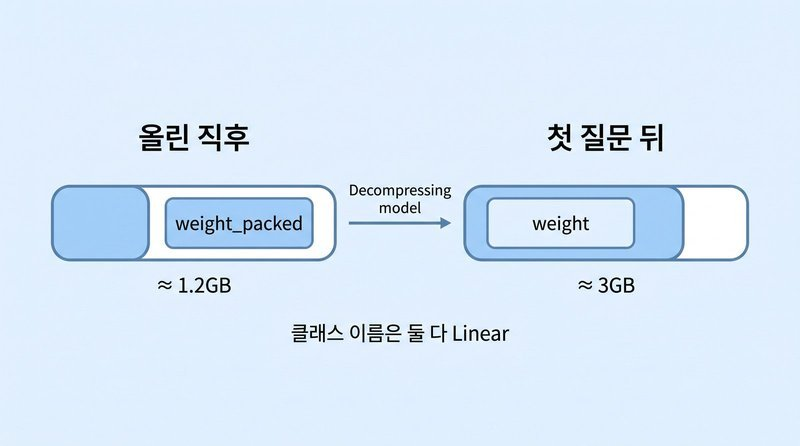

*compressed-tensors 파일은 transformers에서 첫 계산에 풀리므로 매개변수 이름과 메모리로 확인합니다.*